# Library and settings

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os

os.chdir("..")

In [3]:
from src.utility import *

from contextlib import contextmanager
import gc
from itertools import product, chain
import matplotlib.pyplot as plt
import networkx as nx
from networkx.algorithms import approximation
import numpy as np
import pandas as pd
import pickle
import torch
import torch.nn.functional as F
import torch_geometric as pyg
from torch_geometric.data import HeteroData
from torch_geometric.utils import scatter, degree
from torch_geometric.explain import Explainer, GNNExplainer
import types
from tqdm import tqdm
import warnings

c:\Users\tharg\anaconda3\envs\gnn_cf\Lib\site-packages\wikidataintegrator\__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


In [4]:
device = pyg.device("cuda")
# torch.manual_seed(0)

# Construct a graph

In [5]:
# TODO: Figure out why these have duplicates. But I probably can't be bothered.
g_uni_df = datasets.Dataset.load_from_disk(
    in_data_dir("three_hop_neighbors_with_universities_final")
).to_pandas().drop_duplicates(["subject", "relation", "object"], ignore_index=True)

g_nuni_df = datasets.Dataset.load_from_disk(
    in_data_dir("four_hop_neighbors_final")
).to_pandas().drop_duplicates(["subject", "relation", "object"], ignore_index=True)

wikifake_uni_df = datasets.Dataset.load_from_disk(
    in_data_dir("wikifake_plus_three_hop_with_universities_neighbors")
).to_pandas()

wikifake_nuni_df = datasets.Dataset.load_from_disk(
    in_data_dir("wikifake_plus_four_hop_neighbors")
).to_pandas()

In [6]:
g_nuni_one_hop_df = datasets.Dataset.load_from_disk(
    in_data_dir(in_neighbors_dir("one_hop_neighbors_final"))
).to_pandas().drop_duplicates(["subject", "relation", "object"], ignore_index=True)

wikifake_nuni_one_hop_df = datasets.Dataset.load_from_disk(
    in_data_dir("wikifake_plus_one_hop_neighbors")
).to_pandas()

wikifake_nuni_two_hop_df = datasets.Dataset.load_from_disk(
    in_data_dir("wikifake_plus_two_hop_neighbors")
).to_pandas()

g_nuni_two_hop_df = datasets.Dataset.load_from_disk(
    in_data_dir(in_neighbors_dir("two_hop_neighbors_final"))
).to_pandas().drop_duplicates(["subject", "relation", "object"], ignore_index=True)

We've got some more cleaning to do. We also need to clean up the heterogenous NA labels we've accumulated.

In [7]:
nans = ["nan", "<NA>"]
wikifake_uni_df = (
    wikifake_uni_df.map(func=lambda val: None if val in nans else val)
    .drop_duplicates("source")
    .reset_index()
)
wikifake_nuni_df = (
    wikifake_nuni_df.map(func=lambda val: None if val in nans else val)
    .drop_duplicates("source")
    .reset_index()
)
wikifake_nuni_one_hop_df = (
    wikifake_nuni_one_hop_df.map(func=lambda val: None if val in nans else val)
    .drop_duplicates("source")
    .reset_index()
)
wikifake_nuni_two_hop_df = (
    wikifake_nuni_two_hop_df.map(func=lambda val: None if val in nans else val)
    .drop_duplicates("source")
    .reset_index()
)

Now that we'll be working on them as tensors, let's convert the Id field to integer (in fact, I should have done this long ago).

In [8]:
def convert_id_field_to_int_tensor_field(df, field: str):
    # Stip the 'Q' by indexing
    df[field] = df[field].str[1:].values.astype(np.int32)


convert_id_field_to_int_tensor_field(wikifake_uni_df, "source")
convert_id_field_to_int_tensor_field(wikifake_nuni_df, "source")
convert_id_field_to_int_tensor_field(g_uni_df, "subject")
convert_id_field_to_int_tensor_field(g_nuni_df, "subject")
convert_id_field_to_int_tensor_field(g_uni_df, "object")
convert_id_field_to_int_tensor_field(g_nuni_df, "object")

convert_id_field_to_int_tensor_field(wikifake_nuni_one_hop_df, "source")
convert_id_field_to_int_tensor_field(wikifake_nuni_two_hop_df, "source")
convert_id_field_to_int_tensor_field(g_nuni_one_hop_df, "subject")
convert_id_field_to_int_tensor_field(g_nuni_one_hop_df, "object")
convert_id_field_to_int_tensor_field(g_nuni_two_hop_df, "object")
convert_id_field_to_int_tensor_field(g_nuni_two_hop_df, "subject")

We've reached the point of wrestling with the encoding of the labels in a way that can be standardized as a tensor. Because I don't yet know how bad downstream complexity will be, I think I will start with the simplest possible encoding, a simple scalar per item, along with the number of labels, since a high- or low score means less if based on few labels, and then expand it later if possible. One possible expansion is to simply include non-ordinal features like variance among datasets or maximum distance.

In [9]:
g_uni_df
g_nuni_df

,subject,relation,object,index,subjectLabel,relationLabel,objectLabel,subjectDescription,objectDescription,objectClassLabel,subjectClassLabel,__index_level_0__,subjectCategory,objectCategory
0,100277117,P1416,6818913,2,Meredith Herald,affiliation,Meredith College,"newspaper published in Raleigh, North Carolina","liberal arts women's college in Raleigh, North...",nonprofit organization,None,0,data,organization
1,100292619,P1416,2902978,3,The Davidsonian,affiliation,Davidson College,"newspaper published in Davidson, North Carolina","US liberal arts college in Davidson, North Car...",nonprofit organization,None,1,data,organization
2,1003,P1416,1071706,0,Solidarity,affiliation,International Trade Union Confederation,Polish trade union federation evolved into bro...,global trade union federation,nonprofit organization,None,2,organization,organization
3,100364318,P1416,61847315,6,OSMCha,affiliation,OpenStreetMap U.S.,Web application for reviewing changes to OpenS...,American nonprofit organization,None,website,3,organization,organization
4,100750159,P1416,668944,1,Swiss Lithographers' Union,affiliation,Swiss Trade Union Confederation,Swiss trade union,Swiss umbrella organization of trade unions,None,"business and professional associations, unions",4,data,organization
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
61292,839150,P170,483325,2,The Ellen DeGeneres Show,creator,Ellen DeGeneres,American daytime television variety comedy tal...,"American comedian, television host, actress, a...",celebrity,None,4470,organization,organization
61293,904463,P170,263598,3,Ukrainska Pravda,creator,Heorhii Gongadze,Ukrainian online newspaper,Ukrainian journalist,celebrity,None,4471,organization,organization
61294,918,P170,335552,0,X,creator,Jack Dorsey,American social networking service founded in ...,American software entrepreneur and co-founder ...,researcher,None,4472,data,organization
61295,129264284,P1416,327591,0,Michael Robien,affiliation,independent politician,German politician,individual not affiliated to any political party,None,politician,4473,organization,organization


In [10]:
def __retrieve_labels(label_map_column: pd.Series, key: str) -> pd.Series:
    return label_map_column.apply(
        lambda m: eval(str(m))[key] if m is not None else None
    )


def __labels_to_float(label_conversion: Callable, labels: Iterable):
    return torch.nanmean(
        torch.tensor(
            [
                label_conversion(label)
                for label in labels
                if label_conversion(label) is not None
            ]
        )
    )


def __label_maps_to_scores(
    label_maps: pd.Series,
    dataset_name: str,
    label_conversion: Union[dict, Callable],
):
    if isinstance(label_conversion, Callable):
        label_conversion_ = lambda label: (
            label_conversion(label)
            if label_conversion(label) is not None
            else float("nan")
        )
    elif isinstance(label_conversion, dict):  # If dict
        label_conversion_ = lambda label: (
            label_conversion[label]
            if label_conversion[label] is not None
            else float("nan")
        )
    labels = __retrieve_labels(label_maps, dataset_name)
    scores = labels.apply(
            lambda row: (
                __labels_to_float(label_conversion_, row)
                if row is not None
                else float("nan")
            )
        )
    num_labels = labels.apply(lambda row: len(row) if row is not None else 0)
    return (scores, num_labels)


def add_tensor_column_from_label_map_column(
    dataset: DatasetObject, label_map_col="merged_dataset_label_map"
):
    label_maps = dataset[label_map_col]
    # AVeriTeC: {Refuted, Conflicting Evidence/Cherrypicking, Supported, Not Enough Evidence}; multiple scores
    averitec_to_float = {
        "Refuted": 0.0,
        "Conflicting Evidence/Cherrypicking": 0.5,
        "Supported": 1.0,
        "Not Enough Evidence": None,
    }

    averitec_scores, num_averitec_labels = __label_maps_to_scores(
        label_maps, "AVeriTeC", averitec_to_float
    )
    # DomainRatings (can be inherited directly)
    # We still need to add an identity function to pass it through
    # __label_maps_to_scores
    domain_ratings_scores, num_domain_ratings_labels = __label_maps_to_scores(
        label_maps, "Domain Ratings", lambda x: x
    )
    # DRUID+: {False, Half True, True}; multiple
    druid_to_float = {"False": 0.0, "Half True": 0.5, "True": 1.0}
    druid_scores, num_druid_labels = __label_maps_to_scores(
        label_maps, "DRUID+", druid_to_float
    )
    # Emergent.Info: {false, true, Unverified}; multiple
    emergent_to_float = {"false": 0.0, "true": 1.0, "Unverified": None}
    emergent_scores, num_emergent_labels = __label_maps_to_scores(
        label_maps, "Emergent.Info", emergent_to_float
    )
    # FakeHealth: [0, 5]; multiple
    fakehealth_to_float = lambda f: int(f) / 5
    fakehealth_scores, num_fakehealth_labels = __label_maps_to_scores(
        label_maps, "FakeHealth", fakehealth_to_float
    )
    # FakeNewsCorpus: {questionable, fake}; multi
    fakenewscorpus_to_float = {"questionable": 0.25, "fake": 0.0}
    fakenewscorpus_scores, num_fakenewscorpus_labels = __label_maps_to_scores(
        label_maps, "FakeNewsCorpus", fakenewscorpus_to_float
    )
    # FakeNewsNet: binary; multi
    # I.e. apply direct float conversion
    fakenewsnet_scores, num_fakenewsnet_labels = __label_maps_to_scores(
        label_maps, "FakeNewsNet", float
    )
    # GossipCop: binary; multi
    gossipcop_scores, num_gossipcop_labels = __label_maps_to_scores(
        label_maps, "GossipCop", float
    )
    # Liar-PLUS: Truth-o-meter; multi
    # Making it agnostic, just in case
    truth_o_meter_to_float = {
        "pants fire": 0.0,
        "pants-fire": 0.0,
        "false": 1 / 5,
        # It appears the labels may have changed. Liar-PLUS uses 'barely true'
        # whereas MultiFC uses 'mostly false'. The former is not listed in
        # their official guide to the scoring system.
        "barely true": 2 / 5,
        "barely-true": 2 / 5,
        "mostly false": 2 / 5,
        "mostly-false": 2 / 5,
        "half true": 3 / 5,
        "half-true": 3 / 5,
        "mostly true": 4 / 5,
        "mostly-true": 4 / 5,
        "true": 1.0,
    }
    liar_plus_scores, num_liar_plus_labels = __label_maps_to_scores(
        label_maps, "Liar-PLUS", truth_o_meter_to_float
    )
    # Reminder for written thesis: I skipped the Credibility ratings because they contain Factuality but also the other factors as well, especially bias! as well as popularity.
    # MisInfo.General: Factuality in {'very high', 'high', 'mostly factual', 'mixed' 'low' 'very low'}, Credibility in {'high', 'medium', 'low'}; single
    # These are slightly iffy.
    misinfo_general_factuality_to_float = {
        "Very Low": 0.0,
        "Low": 1 / 5,
        "Mixed": 2 / 5,
        "Mostly Factual": 3 / 5,
        "High": 4 / 5,
        "Very High": 1.0,
    }
    misinfo_general_conspiracy_to_float = {
        "Tin Foil Hat": 0.0,
        "Quackery": 1 / 6,
        "Strong": 2 / 6,
        "Moderate": 3 / 6,
        "Mild": 4 / 6,
        "Weak": 5 / 6,
        None: 1.0,
    }
    misinfo_general_pseudosci_to_float = {
        "Quackery": 0.0,
        "Strong": 1 / 5,
        "Moderate": 2 / 5,
        "Mild": 3 / 5,
        "Weak": 4 / 5,
        None: 1.0,
    }
    misinfo_general_scores, num_misinfo_general_labels = __label_maps_to_scores(
        label_maps,
        "MisInfo General",
        lambda d: (
            torch.nanmean(
                torch.tensor(
                    [
                        (
                            misinfo_general_factuality_to_float[d["factuality"]]
                            if d["factuality"]
                            else float("nan")
                        ),
                        misinfo_general_conspiracy_to_float[d["conspiracy"]],
                        misinfo_general_pseudosci_to_float[d["pseudosci"]],
                    ]
                )
            )
        ),
    )  # There appear to be entries without factuality scores. Let's drop them.
    # MM-Covid19: {real, fake}; multi
    mmcovid19_to_float = {"real": 1.0, "fake": 0.0}
    mmcovid19_scores, num_mmcovid19_labels = __label_maps_to_scores(
        label_maps, "MM-COVID19", mmcovid19_to_float
    )
    # MultiFC: Truth-O-Meter (for our subset)
    multifc_scores, num_multifc_labels = __label_maps_to_scores(
        label_maps, "MultiFC", truth_o_meter_to_float
    )
    # News Media Reliability EMNLP: {low, mixed, high}; single
    #  This seems all-None. Maybe no labeled source survived the filters?
    news_media_reliability_emnlp_to_float = {
        "low": 0.0,
        "mixed": 0.5,
        "high": 1.0,
    }
    (
        news_media_reliability_emnlp_scores,
        num_news_media_reliability_emnlp_labels,
    ) = __label_maps_to_scores(
        label_maps,
        "News Media Reliability EMNLP",
        news_media_reliability_emnlp_to_float,
    )
    # PolitiFact Fact Check: Truth-o-meter; single
    politifact_fact_check_scores, num_politifact_fact_check_labels = (
        __label_maps_to_scores(
            label_maps,
            "PolitiFact Fact Check",
            truth_o_meter_to_float,
        )
    )
    # ReCoVery: {0, 1}; single publisher, multiple authors
    recovery_scores, num_recovery_labels = __label_maps_to_scores(
        label_maps, "ReCoVery", float
    )

    # Could also try torch.hstack
    scores = torch.nanmean(
        torch.tensor(
            [
                averitec_scores,
                domain_ratings_scores,
                druid_scores,
                emergent_scores,
                fakehealth_scores,
                fakenewscorpus_scores,
                fakenewsnet_scores,
                gossipcop_scores,
                liar_plus_scores,
                misinfo_general_scores,
                mmcovid19_scores,
                multifc_scores,
                news_media_reliability_emnlp_scores,
                politifact_fact_check_scores,
                recovery_scores,
            ]
        ),
        dim=0,
    )
    num_labels = torch.nansum(
        torch.tensor(
            [
                num_averitec_labels,
                num_domain_ratings_labels,
                num_druid_labels,
                num_emergent_labels,
                num_fakehealth_labels,
                num_fakenewscorpus_labels,
                num_fakenewsnet_labels,
                num_gossipcop_labels,
                num_liar_plus_labels,
                num_misinfo_general_labels,
                num_mmcovid19_labels,
                num_multifc_labels,
                num_news_media_reliability_emnlp_labels,
                num_politifact_fact_check_labels,
                num_recovery_labels,
            ]
        ),
        dim=0,
    )
    # The num_labels attribute is slightly misleading. It should be more
    # properly understood as "num_useful_labels", where those labels
    # whose associated scores are only None are not counted. This helps
    # in NaN-masking downstream.
    num_labels[scores.isnan()] = 0

    dataset["score"] = scores.cpu()
    dataset["numLabels"] = num_labels.cpu()
    return dataset


wikifake_uni_df = add_tensor_column_from_label_map_column(wikifake_uni_df)
wikifake_nuni_df = add_tensor_column_from_label_map_column(
    wikifake_nuni_df
)

wikifake_uni_df
wikifake_nuni_df

,index,source,sourceLabel,sourceDescription,sourceCategory,source_name,sourceClassLabel_from_nl,url,bias_from_nl,dataset_label_map_from_nl,sourceClassLabels,sourceClassLabel_from_domain,website,bias_from_domain,dataset_label_map_from_domain,merged_dataset_label_map,merged_bias,score,numLabels
0,0,1000479,Boston Children's Hospital,"children's hospital in Boston, Massachusetts, ...",organization,boston children's hospital,organization,//www.wikidata.org/wiki/Q1000479,None,{'FakeHealth': ['4']},organization,None,None,None,None,"{'AVeriTeC': None, 'Domain Ratings': None, 'DR...",None,0.800000,1
1,1,100281204,The Rock Island Argus,"newspaper published in Rock Island, Illinois",organization,None,None,None,None,None,publication,publication,https://qconline.com/,None,{'Domain Ratings': [0.581255507206459]},"{'AVeriTeC': None, 'Domain Ratings': [0.581255...",None,0.581255,1
2,2,100285264,The Town Talk,"newspaper published in Alexandria, Louisiana",organization,None,None,None,None,None,organization,organization,https://www.thetowntalk.com,None,{'Domain Ratings': [0.879334607656032]},"{'AVeriTeC': None, 'Domain Ratings': [0.879334...",None,0.879335,1
3,3,100285448,The True Voter,"newspaper published in Smith Center, Kansas",organization,true vote,organization,//www.wikidata.org/wiki/Q100285448,None,{'Liar-PLUS': ['pants-fire']},organization,None,None,None,None,"{'AVeriTeC': None, 'Domain Ratings': None, 'DR...",None,0.000000,1
4,4,100289468,The Coastland Times,"newspaper published in Manteo, Dare County, No...",organization,None,None,None,None,None,publication,publication,https://www.thecoastlandtimes.com,None,{'Domain Ratings': [0.653315560209103]},"{'AVeriTeC': None, 'Domain Ratings': [0.653315...",None,0.653316,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
53299,55618,98533,Barbara Stollberg-Rilinger,German historian,person,None,None,None,None,None,['knowledge worker'],None,None,None,None,None,None,NaN,0
53300,55619,98698646,Jesper Rosener,None,person,None,None,None,None,None,['leader'],None,None,None,None,None,None,NaN,0
53301,55620,98867304,Ivana Radačić,member of the UN Working Group on the Issue of...,person,None,None,None,None,None,['scholar'],None,None,None,None,None,None,NaN,0
53302,55621,993132,Stefan Kölbl,German manager,person,None,None,None,None,None,['manager'],None,None,None,None,None,None,NaN,0


In [11]:
wikifake_nuni_one_hop_df = add_tensor_column_from_label_map_column(wikifake_nuni_one_hop_df)
wikifake_nuni_two_hop_df = add_tensor_column_from_label_map_column(wikifake_nuni_two_hop_df)

In [12]:
wikifake_uni_df.sort_values(by=["score", "numLabels"], ascending=[True, False])[:10]
wikifake_nuni_df.sort_values(by=["score", "numLabels"], ascending=[True, False])[:10]

,index,source,sourceLabel,sourceDescription,sourceCategory,source_name,sourceClassLabel_from_nl,url,bias_from_nl,dataset_label_map_from_nl,sourceClassLabels,sourceClassLabel_from_domain,website,bias_from_domain,dataset_label_map_from_domain,merged_dataset_label_map,merged_bias,score,numLabels
651,651,127162502,Threads thread,individual post on Meta's Threads social network,data,threads post,publication,//www.wikidata.org/wiki/Q127162502,None,"{'DRUID+': ['False', 'False', 'False', 'False'...",publication,None,None,None,None,"{'AVeriTeC': None, 'Domain Ratings': None, 'DR...",None,0.0,244
2666,2666,37312,Internet Movie Database,online database of information related to film...,organization,None,None,None,None,None,organization,organization,https://www.imdb.com/,None,"{'GossipCop': [False, False, False, False, Fal...","{'AVeriTeC': None, 'Domain Ratings': None, 'DR...",None,0.0,145
1439,1439,18572033,Sputnik,Russian government news agency,organization,sputnik news,organization,//www.wikidata.org/wiki/Q18572033,right,"{'ReCoVery': ['0', '0', '0', '0', '0', '0', '0...",organization,None,None,None,None,"{'AVeriTeC': None, 'Domain Ratings': None, 'DR...",['right'],0.0,144
6054,6054,84497003,Instagram post,post hosted on the Instagram photo-sharing and...,data,instagram post,publication,//www.wikidata.org/wiki/Q84497003,None,"{'DRUID+': ['False', 'False', 'False', 'False'...",publication,None,None,None,None,"{'AVeriTeC': None, 'Domain Ratings': None, 'DR...",None,0.0,144
48231,48235,91988138,Peter A. McCullough,American cardiologist and medical professor,person,peter mccullough,activist,//www.wikidata.org/wiki/Q91988138,None,"{'DRUID+': ['False', 'False', 'False', 'False'...",activist,None,None,None,None,"{'AVeriTeC': None, 'Domain Ratings': None, 'DR...",None,0.0,118
48263,48267,945385,Ian Plimer,Australian geologist,person,ian plimer,scholar,//www.wikidata.org/wiki/Q945385,None,"{'DRUID+': ['False', 'False', 'False', 'False'...",scholar,None,None,None,None,"{'AVeriTeC': None, 'Domain Ratings': None, 'DR...",None,0.0,90
46585,46587,335078,Nigel Lawson,British peer and politician (1932–2023),person,nigel lawson,media professional,//www.wikidata.org/wiki/Q335078,None,"{'DRUID+': ['False', 'False', 'False', 'False'...",media professional,None,None,None,None,"{'AVeriTeC': None, 'Domain Ratings': None, 'DR...",None,0.0,55
45719,45720,1352872,Robert F. Kennedy Jr.,"American politician, environmental lawyer, ant...",person,robert f. kennedy jr.,jurist,//www.wikidata.org/wiki/Q1352872,None,"{'DRUID+': ['False', 'False', 'False', 'False'...",jurist,None,None,None,None,"{'AVeriTeC': None, 'Domain Ratings': None, 'DR...",None,0.0,51
45490,45491,108441764,James H. Thorp,American biologist,person,james thorp,non-fiction writer,//www.wikidata.org/wiki/Q108441764,None,"{'DRUID+': ['False', 'False', 'False', 'False'...",non-fiction writer,None,None,None,None,"{'AVeriTeC': None, 'Domain Ratings': None, 'DR...",None,0.0,48
45955,45956,16729907,Brian Hooker,American bioengineer,person,brian hooker,non-fiction writer,//www.wikidata.org/wiki/Q16729907,None,"{'DRUID+': ['False', 'False', 'False', 'False'...",non-fiction writer,None,None,None,None,"{'AVeriTeC': None, 'Domain Ratings': None, 'DR...",None,0.0,45


In [13]:
print(wikifake_uni_df.score.mean())

0.6149287194277084


In [14]:
DTYPE = torch.float32
torch.set_default_dtype(DTYPE)

### Welford's algorithm

Welford's algorithm for single-pass approximations of mean and std.

In [15]:
#### 2-dimensional Welford.

class TorchWelford():
    def __init__(self, length, width, verbose=False):
        """
        The assumption is that 'length' is the number of edge types and the 'width' is the number of nodes.
        """
        self.t = torch.zeros((length, width, 3))
        self.width = width
        self.verbose = verbose


    def __call__(self, update:torch.Tensor, counts, idx:int):
        """
        Update the running approximations.
        """
        assert len(update) == self.t.shape[1] and idx < len(self), \
        f"Update length of {len(update)} is not compatible with Welford length of {self.t.shape[1]} or index {idx} does not match shape {self.t.shape}"
        if self.verbose:
            print(f"Before update:\nCount:\n{self.count}\n\nMean:\n{self.mean}\n\n\n")
        self.count[idx] += counts
        delta = (update - self.mean[idx])*(update > 0)
        self.mean[idx] = self.mean[idx] + (delta / torch.where(update > 0, self.count[idx], 1))
        delta2 = update - self.mean[idx]
        self.M2[idx] = self.M2[idx] + delta*delta2

        if self.verbose:
            print(f"After update:\n{update}\n\nCount:\n{self.count}\n\nMean:\n{self.mean}\n\nT:\n{self.t}\n\n\n\n")


    def __len__(self):
        return len(self.t)


    def __repr__(self):
        return "[type idx, [counts, means, M2s]]:\n" + self.t.__repr__()


    @property
    def count(self):
        return self.t[:,:,0]
    @count.setter
    def count(self, update):
        self.t[:,:,0] = update


    @property
    def mean(self):
        return self.t[:,:,1]
    @mean.setter
    def mean(self, update):
        self.t[:,:,1] = update


    @property
    def M2(self):
        return self.t[:,:,2]
    @M2.setter
    def M2(self, update):
        self.t[:,:,2] = update

    def update_count(self, update, idx):
        self.t[:,:,0][idx] += torch.where(update > 0, 1, 0)



    def finalize(self):
        """
        The first output axis is the means, the second is the
        variances.
        """
        if self.verbose:
            print(f"About to finalize. Before final normalization, t is\n{self.t}\n\n")
        t_out = self.t[:,:,1:].clone()
        t_out[:,:,1] /= torch.where(self.count > 0, self.count, 1)
        if self.verbose:
            print(f"Final t is\n{t_out}.\n\n")
        return t_out


    def reset(self):
        self.__init__(len(self), self.width)


    @property
    def T(self):
        return self.t.T

    def to(self, device:str):
        self.t = self.t.to(device)
        return self

## Construct the graph object and associated auxiliary

In [78]:
def __derive_edge_type_dict(g_dict: dict) -> dict[dict[list[str]]]:
    """
    Create a recursive dict based on the edge-type, source-type, sink-type in a heterogeneous graph for more understandable iteration.
    """
    # Sort the edge types by (source, relation, sink)
    sorted_edge_types = sorted(
        g_dict["g"].edge_types,
        key=lambda sro_triple: (sro_triple[0], sro_triple[1], sro_triple[2]),
    )
    prev_source_type = ""
    prev_edge_type = ""
    out = {}
    for source_type, edge_type, sink_type in sorted_edge_types:
        if source_type != prev_source_type:
            out[source_type] = {}
        if edge_type != prev_edge_type:
            out[source_type][edge_type] = []
        out[source_type][edge_type].append(sink_type)
        prev_source_type = source_type
        prev_edge_type = edge_type
    return out


def __test_reconstituted_heterogeneous_graph_integrity(g):
    """
    g != g.to_homogeneous().to_heterogeneous()
    It is not clear how .__eq__ is implemented. Instead, we test here whether we are happy with the reconstituted graph.
    """
    g_ = deepcopy(g).to_homogeneous().to_heterogeneous()
    for node_type in g.node_types:
        for attr in [
            "y",
            "id",
            "is_labelled",
            "num_labels",
            "score",
            "train_mask",
            "validation_mask",
            "test_mask",
            "x",
        ]:
            value_x = getattr(g[node_type], attr)
            value_y = getattr(g_[node_type], attr)
            x = value_x[~value_x.isnan()]
            y = value_y[~value_y.isnan()]
            assert torch.all(
                x == y
            ), f"{x}\n\nis not\n\n{y}\n\nAt indices\n\n{torch.where(x != y)}"
    for edge_type in g.edge_types:
        assert torch.all(
            g[edge_type]["edge_index"] == g_[edge_type]["edge_index"]
        ), torch.where(
            torch.tensor(g[edge_type]["edge_index"])
            != torch.tensor(g_[edge_type]["edge_index"])
        )
    print("Reconstituted graph is satisfactory!")


def dataset_to_graph_dict(
    dataset: pd.DataFrame,
    nodes_df: pd.DataFrame,
    node_id="source",
    nodetype="sourceCategory",
    source_id="subject",
    sourcetype="subjectCategory",
    edge="relationLabel",
    sink_id="object",
    sinktype="objectCategory",
    impute_missing_scores_with: Optional[Literal["mean", "median", "zero"]] = None,
    train_test_split=(70, 15, 15),
    keep_isolated_nodes=True,
    mode: Union[Literal["full"], Literal["compact"]] = "full",
    fold: Optional[int] = None,
) -> pyg.data.HeteroData:
    assert len(train_test_split) == 3 and sum(train_test_split) == 100
    _, validation_prop, test_prop = train_test_split
    if impute_missing_scores_with:
        assert impute_missing_scores_with in ["mean", "median", "zero"]
    g = pyg.data.HeteroData()
    dataset["typedSubjectIdx"] = 0
    dataset["typedObjectIdx"] = 0
    dataset["subjectCategory"] = dataset.merge(
        nodes_df, how="left", left_on="subject", right_on="source"
    )["sourceCategory"]
    dataset["objectCategory"] = dataset.merge(
        nodes_df, how="left", left_on="object", right_on="source"
    )["sourceCategory"]
    # When we remove isolated nodes later, non-Torch metadata will be
    # dropped, so we do not assign node labels (string-arrays) before
    # last, and we have to maintain an index for them to retrieve them
    # after graph pruning.
    node_labels_dict = {}
    for node_type in nodes_df[nodetype].unique():
        # Filter the relevant subsets upfront
        subject_subset = dataset[dataset[sourcetype] == node_type].copy()
        object_subset = dataset[dataset[sinktype] == node_type].copy()
        subset_nodes = nodes_df[nodes_df[nodetype] == node_type]
        subject_subset["typedSubjectIdx"] = pd.Categorical(
            subject_subset[source_id],
            categories=subset_nodes[node_id],
        ).codes
        object_subset["typedObjectIdx"] = pd.Categorical(
            object_subset[sink_id],
            categories=subset_nodes[node_id],
        ).codes
        # WARNING: If you convert these to float32, you will have
        # overflow
        g[node_type].id = torch.tensor(
            nodes_df[nodes_df[nodetype] == node_type]["source"].values
        ).to(dtype=torch.int32)
        g[node_type].num_nodes = len(g[node_type].id)
        g[node_type].num_labels = torch.tensor(
            nodes_df[nodes_df[nodetype] == node_type]["numLabels"].values
        ).to(dtype=DTYPE)

        # Associate the nodes with their labels and their ids, because
        # the implicit index will be dropped when we prune isolated
        # nodes.
        node_labels_dict[node_type] = (
            nodes_df[nodes_df[nodetype] == node_type]["sourceLabel"].values,
            g[node_type].id,
        )
        scores = torch.tensor(
            nodes_df[nodes_df[nodetype] == node_type]["score"].values
        ).to(dtype=DTYPE)
        g[node_type].score = scores
        # Keep NaNs on this tensor to help derive a mask later
        g[node_type].y = scores.clone()
        # Hard-coding this mask comes in handy
        g[node_type].is_labelled = g[node_type].num_labels > 0
        assert (
            torch.sum(g[node_type].score[g[node_type].is_labelled].isnan()) == 0
        ), node_type
        dataset.loc[dataset[sourcetype] == node_type, "typedSubjectIdx"] = (
            subject_subset["typedSubjectIdx"]
        )
        # Construct node masks by generating standard uniform
        # values for each node, zeroing those that are associated
        # with unlabeled nodes, and converting by thresholds to boolean
        # tensors.
        if fold:
            # Assume 10-fold validation
            num_labeled_nodes = len(g[node_type].is_labelled)
            validation_mask = torch.zeros(num_labeled_nodes, dtype=bool)
            validation_mask[
                int(num_labeled_nodes / 10 * fold) : int(
                    num_labeled_nodes / 10 * (fold + 1)
                )
            ] = True
            train_mask = ~validation_mask
            test_mask = validation_mask
        else:
            probability_tensor = torch.rand(len(g[node_type].is_labelled))
            validation_mask = torch.where(
                probability_tensor <= validation_prop / 100, True, False
            )
            test_mask = torch.where(
                torch.logical_and(
                    probability_tensor > validation_prop / 100,
                    probability_tensor <= (validation_prop + test_prop) / 100,
                ),
                True,
                False,
            )
            train_mask = ~torch.logical_or(validation_mask, test_mask)
        for mask in [validation_mask, test_mask, train_mask]:
            mask[~g[node_type].is_labelled] = False
            assert torch.sum(g[node_type].score[mask].isnan()) == 0, (node_type, mask)
        g[node_type].validation_mask = validation_mask
        g[node_type].test_mask = test_mask
        g[node_type].train_mask = train_mask
        dataset.loc[dataset[sinktype] == node_type, "typedObjectIdx"] = object_subset[
            "typedObjectIdx"
        ]
        g[node_type].num_nodes = len(g[node_type].id)
    # Retrieve category columns
    node_types = nodes_df[nodetype].unique()
    for source_type, sink_type in product(node_types, node_types):
        for edge_type in dataset[edge].unique():
            pyg_friendly_edge_type = (
                edge_type.replace(" / ", "_or_")
                .replace("/", "_or_")
                .replace(" ", "_")
                .replace("-", "_")
                .replace("(s)", "s")
            )
            g[source_type, pyg_friendly_edge_type, sink_type].edge_index = torch.tensor(
                dataset[
                    (dataset[sourcetype] == source_type)
                    & (dataset[edge] == edge_type)
                    & (dataset[sinktype] == sink_type)
                ][["typedSubjectIdx", "typedObjectIdx"]].values
            ).T
    g_dict = associate_pyg_graph_with_homogeneous_undirected_nx_graph(g)
    feature_map = derive_and_apply_features(g_dict, mode, impute_missing_scores_with)
    # Rerun this now that features are added. A bit lazy.
    g_dict = associate_pyg_graph_with_homogeneous_undirected_nx_graph(g)
    if not (keep_isolated_nodes):
        g = remove_isolated_nodes(g_dict)
        g_dict = associate_pyg_graph_with_homogeneous_undirected_nx_graph(g)
    for node_type in g_dict["g"].node_types:
        node_labels, original_ids = node_labels_dict[node_type]
        mask = torch.isin(original_ids, g_dict["g"][node_type].id)
        # pruned_ids = original_ids.difference(g_dict["g"][node_type].id)
        g[node_type].node_label = node_labels[mask]
    g_dict["g"].validate()
    return g_dict, feature_map


def associate_pyg_graph_with_homogeneous_undirected_nx_graph(
    g: pyg.data.HeteroData,
):
    """
    Generate a dict consisting of:
        * The PyG HeteroData
        * The corresponding homogeneous graph
        * The NetworkX conversion of the homogeneous graph
        * NetworkX node offsets
    The NetworkX offsets map their index to how much higher a NetworkX node index is than the corresponding typed index in the PyG.
    """
    g_homo = g.to_homogeneous()
    g_nx = pyg.utils.to_networkx(g_homo, to_undirected=True)
    nx_node_offsets = torch.zeros(len(g_nx))
    offset = 0
    # Skip the first one, since it has zero offset
    for node_type in g.node_types[:-1]:
        if (num_typed_nodes := g[node_type].num_nodes) > 0:
            offset += num_typed_nodes
            # Have to avoid index errors on subgraphs without all node
            # types present
            if offset < len(nx_node_offsets):
                nx_node_offsets[offset] = num_typed_nodes
    nx_node_offsets = torch.cumsum(nx_node_offsets, 0, dtype=torch.int32)
    return {
        "g": g,
        "g_homo": g_homo,
        "nx": g_nx,
        "nx node offsets": nx_node_offsets,
    }


# Torch named tensors don't play nice here, so here's an explicit feature
# index dict.
def derive_feature_index(g: pyg.data.HeteroData):
    f_idx = {}
    features = [
        "mean score",
        "score var",
        "mean num_labels",
        "num_labels var",
        "relative degree",
    ]
    num_features = len(features)

    for i, node_type in enumerate(g.node_types):
        edges = [edge[1:] for edge in g.edge_types if edge[0] == node_type]
        for j, edge_type in enumerate(edges):
            for k, direction in enumerate(["out", "in"]):
                for l, feature in enumerate(features):
                    f_idx[(node_type, *edge_type, direction, feature)] = (
                        j * 2 * num_features + k * num_features + l
                    )
    return f_idx


def derive_and_apply_features(
    g_dict: dict,
    mode: Union[Literal["full"], Literal["compact"]],
    impute_missing_scores_with: Optional[Literal["mean", "median"]] = None,
) -> dict:
    """
    This is an inplace operation, but returns a feature map!

    If mode == "compact", the features will be averaged across all edge-types. If "full", there is a feature for each edge type (hence fairly sparse).
    """
    assert mode in ["full", "compact"]
    g = g_dict["g"]
    average_score = get_average_score(g_dict)
    average_num_labels = get_average_num_labels(g_dict)

    edge_type_dict = __derive_edge_type_dict(g_dict)
    # Replace NaNs with imputed values
    if method := impute_missing_scores_with:
        for _type in g.node_types:
            if method == "mean":
                g[_type].score = g[_type].score.nan_to_num(nan=average_score)
                g[_type].num_labels[g[_type].num_labels < 1] = average_num_labels
            elif method == "median":
                g[_type].score = g[_type].score.nan_to_num(
                    nan=g[_type].score.nanmedian()
                )
                g[_type].num_labels = g[_type].num_labels.nan_to_num(
                    nan=g[_type].num_labels.nanmedian()
                )
            elif method == "zero":
                g[_type].score = g[_type].score.nan_to_num(nan=0)
                g[_type].num_labels = g[_type].num_labels.nan_to_num(nan=0)
    feature_map = {}
    edges_and_size = zip(g.edge_types, g.edge_index_dict.values())
    populated_edge_types = set([e[1] for (e, s) in edges_and_size if s.shape[1] > 0])
    num_populated_edge_types = len(populated_edge_types)
    feature_map["num_populated_edge_types"] = num_populated_edge_types
    feature_map["features"] = {
        "metrics": [
            "mean neighbor score",
            "neighbor score variance",
            "mean neighbor num_labels",
            "neighbor num_labels variance",
            "degree",
        ],
        "directions": ["out", "in"],
        "populated edgetypes": populated_edge_types,
    }
    if mode == "full":
        feature_map["populated edgetypes"] = populated_edge_types
        flat_feature_list = [
            (metric, direction, edge_type)
            for metric in feature_map["features"]["metrics"]
            for direction in feature_map["features"]["directions"]
            for edge_type in feature_map["populated edgetypes"]
        ]
    else:
        flat_feature_list = [
            (metric, direction)
            for metric in feature_map["features"]["metrics"]
            for direction in feature_map["features"]["directions"]
        ]
    feature_map["flat feature index"] = list(
        zip(flat_feature_list, range(len(flat_feature_list)))
    )
    for k, (source_type, edge_sink_type_dict) in enumerate(edge_type_dict.items()):
        num_typed_nodes = g[source_type].num_nodes
        feature_shape = (num_populated_edge_types, num_typed_nodes)
        num_out_neighbors_per_type = torch.zeros(feature_shape)
        num_in_neighbors_per_type = torch.zeros(feature_shape)
        approximate_num_out_labels_welford = TorchWelford(*feature_shape)
        approximate_num_in_labels_welford = TorchWelford(*feature_shape)
        approximate_in_scores_welford = TorchWelford(*feature_shape)
        approximate_out_scores_welford = TorchWelford(*feature_shape, verbose=True)

        feature_map[source_type] = {
            "index": k,
            "num_nodes": num_typed_nodes,
            "feature shape": (num_typed_nodes, len(flat_feature_list)),
        }
        for i, (edge_type, sink_type_list) in enumerate(edge_sink_type_dict.items()):
            feature_map[source_type][edge_type] = {
                "sink_type_list": sink_type_list,
            }
            for sink_type in sink_type_list:
                srcs, snks = g[source_type, edge_type, sink_type].edge_index
                # Scatter doesn't fail gracefully on empty indices
                if len(srcs):
                    num_out_neighbors_per_type[i] += degree(
                        srcs, num_nodes=num_typed_nodes
                    )
                    update, counts = generate_scatter_update_and_counts(
                        num_typed_nodes, g[sink_type].num_labels, srcs, snks
                    )
                    approximate_num_out_labels_welford(update, counts, i)

                    update, counts = generate_scatter_update_and_counts(
                        num_typed_nodes, g[sink_type].score, srcs, snks
                    )

                    approximate_out_scores_welford(update, counts, i)
                # Consider the [i]nverse relation (sink -> source) for
                # calculating incoming edge information.
                i_srcs, i_snks = g[sink_type, edge_type, source_type].edge_index
                if len(i_snks):
                    num_in_neighbors_per_type[i] += degree(
                        i_snks, num_nodes=num_typed_nodes
                    )

                    update, counts = generate_scatter_update_and_counts(
                        num_typed_nodes, g[sink_type].num_labels, i_snks, i_srcs
                    )
                    approximate_num_in_labels_welford(update, counts, i)

                    update, counts = generate_scatter_update_and_counts(
                        num_typed_nodes, g[sink_type].score, i_snks, i_srcs
                    )
                    approximate_in_scores_welford(update, counts, i)

        # Finalize Welfords
        in_edge_typewise_score_approximations = approximate_in_scores_welford.finalize()
        in_edge_typewise_num_labels_approximations = (
            approximate_num_in_labels_welford.finalize()
        )
        out_edge_typewise_num_labels_approximations = (
            approximate_num_out_labels_welford.finalize()
        )
        out_edge_typewise_score_approximations = (
            approximate_out_scores_welford.finalize()
        )

        # Unpack approximations
        out_edge_typewise_score_mean, out_edge_typewise_score_variance = torch.unbind(
            out_edge_typewise_score_approximations, dim=2
        )
        in_edge_typewise_score_mean, in_edge_typewise_score_variance = torch.unbind(
            in_edge_typewise_score_approximations, dim=2
        )

        out_edge_typewise_num_labels_mean, out_edge_typewise_num_labels_variance = (
            torch.unbind(out_edge_typewise_num_labels_approximations, dim=2)
        )
        in_edge_typewise_num_labels_mean, in_edge_typewise_num_labels_variance = (
            torch.unbind(in_edge_typewise_num_labels_approximations, dim=2)
        )

        # Relativize approximations
        in_edge_typewise_score_mean /= average_score / num_populated_edge_types
        out_edge_typewise_score_mean /= average_score / num_populated_edge_types

        in_edge_typewise_num_labels_mean /= (
            average_num_labels / num_populated_edge_types
        )
        out_edge_typewise_num_labels_mean /= (
            average_num_labels / num_populated_edge_types
        )

        # Relativize degree
        avg_in_degrees = num_in_neighbors_per_type.mean(dim=0)
        avg_out_degrees = num_out_neighbors_per_type.mean(dim=0)
        relative_in_degree = (
            num_in_neighbors_per_type
            / torch.where(avg_in_degrees > 0, avg_in_degrees, 1)
            * num_populated_edge_types
        )
        relative_out_degree = (
            num_out_neighbors_per_type
            / torch.where(avg_out_degrees > 0, avg_out_degrees, 1)
            * num_populated_edge_types
        )

        if mode == "full":
            g[source_type].x = torch.hstack(
                [
                    out_edge_typewise_score_mean.T,
                    in_edge_typewise_score_mean.T,
                    out_edge_typewise_score_variance.T,
                    in_edge_typewise_score_variance.T,
                    out_edge_typewise_num_labels_mean.T,
                    in_edge_typewise_num_labels_mean.T,
                    out_edge_typewise_num_labels_variance.T,
                    in_edge_typewise_num_labels_variance.T,
                    relative_in_degree.T,
                    relative_out_degree.T,
                ]
            )
        else:
            g[source_type].x = torch.vstack(
                [
                    out_edge_typewise_score_mean.mean(dim=0),
                    in_edge_typewise_score_mean.mean(dim=0),
                    out_edge_typewise_score_variance.mean(dim=0),
                    in_edge_typewise_score_variance.mean(dim=0),
                    out_edge_typewise_num_labels_mean.mean(dim=0),
                    in_edge_typewise_num_labels_mean.mean(dim=0),
                    out_edge_typewise_num_labels_variance.mean(dim=0),
                    in_edge_typewise_num_labels_variance.mean(dim=0),
                    relative_in_degree.mean(dim=0),
                    relative_out_degree.mean(dim=0),
                ]
            ).T
    return feature_map


def get_average_score(g_dict: dict):
    labels = torch.cat(
        [g_dict["g"][node_type].y for node_type in g_dict["g"].node_types]
    )
    non_nan_labels = labels[~labels.isnan()]
    return torch.sum(non_nan_labels) / len(non_nan_labels)


def get_average_num_labels(g_dict: dict):
    labels = torch.cat(
        [g_dict["g"][node_type].num_labels for node_type in g_dict["g"].node_types]
    )
    nonzero_labels = labels[labels > 0]
    return torch.sum(nonzero_labels) / len(nonzero_labels)


def get_average_in_and_out_degrees(g_dict: dict):
    directed_nx = pyg.utils.to_networkx(g_dict["g"])
    in_degree_tensor = torch.tensor(
        [pair[1] for pair in directed_nx.in_degree()], dtype=int
    )
    out_degree_tensor = torch.tensor(
        [pair[1] for pair in directed_nx.out_degree()], dtype=int
    )
    return (
        float(torch.sum(in_degree_tensor) / len(in_degree_tensor)),
        float(torch.sum(out_degree_tensor) / len(out_degree_tensor)),
    )


def graph_dict_nx_idxs_lookup(
    graph_dict, idxs: Iterable, fields: Union[str, list[str]]
) -> Union[dict[str, torch.Tensor], torch.Tensor]:
    """
    Given a graph dict, a tensor of idxs in the nx version of the graph and the name of a field, retrieve the corresponding set of node attributes from the Heterogeneous graph.
    """
    if isinstance(fields, str):
        fields = [fields]
    # We need to convert it by way of list in case it is a set (which
    # it is)
    idxs = torch.tensor(list(idxs))
    g, g_homo, _, nx_offsets = graph_dict.values()
    type_idxs = g_homo.node_type[idxs]
    out_dict = dict()
    for field in fields:
        out = []
        for node_type_idx, node_type in enumerate(g.node_types):
            idxs_for_type = idxs[type_idxs == node_type_idx]
            if len(idxs_for_type):
                offsets_for_type = nx_offsets[idxs_for_type]
                target = g[node_type][field][idxs_for_type - offsets_for_type]
                # We have to wrap the element in an array if it's single
                out.append(target) if isinstance(target, Iterable) and not isinstance(target, str) else out.append(np.array([target]))
        print(out)
        out_dict[field] = np.concat([tensor for tensor in out])
    if len(fields) == 1:
        return out_dict[field]
    else:
        return out_dict


def pprint_features(g_dict: dict, feature_map, node_type: str):
    """
    Remember that values are relativized!
    """
    g = g_dict["g"]
    for i in range(min(10, g[node_type].num_nodes)):
        print(
            f"\n\nConsider node {g[node_type].node_label[i]} with features\n{g[node_type].x[i]}\n\tThat is,"
        )
        for k, j in feature_map["flat feature index"]:
            print(k, ": ", g[node_type].x[i][j])


def remove_isolated_nodes(g_dict) -> HeteroData:
    g_homo = g_dict["g_homo"]
    isolated_node_index, isolated_edge_type, isolated_node_mask = (
        pyg.utils.remove_isolated_nodes(
            g_homo.edge_index, g_homo.edge_type, num_nodes=g_homo.num_nodes
        )
    )
    g_homo.edge_index = isolated_node_index
    g_homo.edge_type = isolated_edge_type
    for attr in [
        "x",
        "y",
        "id",
        "is_labelled",
        "num_labels",
        "score",
        "train_mask",
        "validation_mask",
        "test_mask",
        "node_type",
    ]:
        setattr(g_homo, attr, getattr(g_homo, attr)[isolated_node_mask])
    g_homo.validate()
    return g_homo.to_heterogeneous()


def zero_padded_neighbor_scatter(
    size, target: torch.Tensor, source_index: torch.Tensor, sink_index: torch.Tensor
):
    """
    At a high level, the point of this function is to push values from a target tensor (e.g. labels) to the indices given in the sink_index, and then push them to those source indices that connect with them given the edge index (source_index, sink_index).

    Can be a bit tricky to wrap your head around. The source_index and sink_index are expected to be the corresponding partners of an edge-index. Given these, take the values from sink_index and map them to the corresponding indices of target (e.g. labels). Then scatter these values to the source_index positions of a zero-tensor.
    """
    return torch.zeros(size, dtype=target.dtype).scatter_reduce(
        dim=0, index=source_index, src=target[sink_index], reduce="sum"
    )


def generate_scatter_update_and_counts(length: int, target: torch.Tensor, srcs, snks):
    update = zero_padded_neighbor_scatter(length, target, srcs, snks)
    counts = zero_padded_neighbor_scatter(length, torch.ones(len(target)), srcs, snks)
    return update, counts

In [41]:
# These are derived from a connected component found below. A connected
# component of ten entities that is 30% labelled.
# print("Small graphs:\n\n\n")
entities_for_debugging = [
    6733367,
    6024198,
    2464129,
    3595638,
    25389797,
    3784687,
    972645,
    46807,
    113974698,
    1954757,
]
sro_df_for_debugging = (
    g_nuni_df[
        g_nuni_df["subject"].isin(entities_for_debugging)
        | g_nuni_df["object"].isin(entities_for_debugging)
    ]
    .copy()
    .reset_index(drop=True)
)
wikifake_df_for_debugging = (
    wikifake_nuni_df[wikifake_nuni_df["source"].isin(entities_for_debugging)]
    .copy()
    .reset_index(drop=True)
)


print("\n\n\nBig graphs:\n\n\n")
g_uni_df_debug = deepcopy(g_uni_df)
wikifake_uni_df_debug = deepcopy(wikifake_uni_df)
wikifake_nuni_df_debug = deepcopy(wikifake_nuni_df)
wikifake_nuni_one_hop_df_debug = deepcopy(wikifake_nuni_one_hop_df)
wikifake_nuni_two_hop_df_debug = deepcopy(wikifake_nuni_two_hop_df)
g_uni_dict, g_uni_feature_map = dataset_to_graph_dict(
    g_uni_df_debug,
    wikifake_uni_df_debug,
    keep_isolated_nodes=False,
    impute_missing_scores_with="mean",
    mode="compact",
)

g_nuni_df_debug = deepcopy(g_nuni_df)
g_nuni_one_hop_df_debug = deepcopy(g_nuni_one_hop_df)
g_nuni_two_hop_df_debug = deepcopy(g_nuni_two_hop_df)
wikifake_nuni_df_debug = deepcopy(wikifake_nuni_df)
g_nuni_dict, g_nuni_feature_map = dataset_to_graph_dict(
    g_nuni_df_debug,
    wikifake_nuni_df_debug,
    keep_isolated_nodes=False,
    impute_missing_scores_with="mean",
    mode="compact",
)

g_nuni_one_hop_dict, g_nuni_one_hop_feature_map = dataset_to_graph_dict(
    g_nuni_one_hop_df_debug,
    wikifake_nuni_one_hop_df_debug,
    keep_isolated_nodes=False,
    impute_missing_scores_with="mean",
    mode="full",
)
g_nuni_two_hop_dict, g_nuni_two_hop_feature_map = dataset_to_graph_dict(
    g_nuni_two_hop_df_debug,
    wikifake_nuni_two_hop_df_debug,
    keep_isolated_nodes=False,
    impute_missing_scores_with="mean",
    mode="full",
)


g_uni_zero_imputed_dict, g_nuni_zero_imputed_feature_map = dataset_to_graph_dict(
    g_nuni_df_debug,
    wikifake_nuni_df_debug,
    keep_isolated_nodes=False,
    impute_missing_scores_with="zero",
    mode="compact",
)

# pprint_features(g_nuni_dict, g_nuni_feature_map, "organization")




Big graphs:



Before update:
Count:
tensor([[0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        ...,
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.]])

Mean:
tensor([[0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        ...,
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.]])



After update:
tensor([0., 0., 0.,  ..., 0., 0., 0.])

Count:
tensor([[0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        ...,
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.]])

Mean:
tensor([[0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],


In [53]:
G_NUNI_FULL_PATH = in_data_dir("g_nuni_dict_full")
G_UNI_FULL_PATH = in_data_dir("g_uni_dict_full")
G_NUNI_FULL_FEATURE_MAP_PATH = in_data_dir("g_nuni_feature_map_full")
G_UNI_FULL_FEATURE_MAP_PATH = in_data_dir("g_uni_feature_map_full")

if os.path.exists(G_NUNI_FULL_PATH):
    with open(G_NUNI_FULL_PATH, "rb") as f:
        g_nuni_dict_full = pickle.load(f)
    with open(G_NUNI_FULL_FEATURE_MAP_PATH, "rb") as f:
        g_nuni_feature_map_full = pickle.load(f)
else:
    g_nuni_dict_full, g_nuni_feature_map_full = dataset_to_graph_dict(
        g_nuni_df_debug,
        wikifake_nuni_df_debug,
        keep_isolated_nodes=False,
        impute_missing_scores_with="mean",
        mode="full"
    )
    with open(G_NUNI_FULL_PATH, "wb") as f:
        pickle.dump(g_nuni_dict_full, f)
    with open(G_NUNI_FULL_FEATURE_MAP_PATH, "wb") as f:
        pickle.dump(g_nuni_feature_map_full, f)

if os.path.exists(G_UNI_FULL_PATH):
    with open(G_UNI_FULL_PATH, "rb") as f:
        g_uni_dict_full = pickle.load(f)
    with open(G_UNI_FULL_FEATURE_MAP_PATH, "rb") as f:
        g_uni_feature_map_full = pickle.load(f)
else:
    g_uni_dict_full, g_uni_feature_map_full = dataset_to_graph_dict(
        g_uni_df_debug,
        wikifake_uni_df_debug,
        keep_isolated_nodes=False,
        impute_missing_scores_with="mean",
        mode="full"
    )
    with open(G_UNI_FULL_PATH, "wb") as f:
        pickle.dump(g_uni_dict_full, f)
    with open(G_UNI_FULL_FEATURE_MAP_PATH, "wb") as f:
        pickle.dump(g_uni_feature_map_full, f)


G_NUNI_COMPACT_PATH = in_data_dir("g_nuni_dict_compact")
G_UNI_COMPACT_PATH = in_data_dir("g_uni_dict_compact")
G_NUNI_COMPACT_FEATURE_MAP_PATH = in_data_dir("g_nuni_feature_map_compact")
G_UNI_COMPACT_FEATURE_MAP_PATH = in_data_dir("g_uni_feature_map_compact")

if os.path.exists(G_NUNI_COMPACT_PATH) and os.path.exists(G_NUNI_COMPACT_FEATURE_MAP_PATH):
    with open(G_NUNI_COMPACT_PATH, "rb") as f:
        g_nuni_dict_compact = pickle.load(f)
    with open(G_NUNI_COMPACT_FEATURE_MAP_PATH, "rb") as f:
        g_nuni_feature_map_compact = pickle.load(f)
else:
    g_nuni_dict_compact, g_nuni_feature_map_compact = dataset_to_graph_dict(
        g_nuni_df_debug,
        wikifake_nuni_df_debug,
        keep_isolated_nodes=False,
        impute_missing_scores_with="mean",
        mode="compact"
    )
    with open(G_NUNI_COMPACT_PATH, "wb") as f:
        pickle.dump(g_nuni_dict_compact, f)
    with open(G_NUNI_COMPACT_PATH, "wb") as f:
        pickle.dump(g_nuni_feature_map_compact, f)

if os.path.exists(G_UNI_COMPACT_PATH):
    with open(G_UNI_COMPACT_PATH, "rb") as f:
        g_uni_dict_compact = pickle.load(f)
    with open(G_UNI_COMPACT_FEATURE_MAP_PATH, "rb") as f:
        g_uni_feature_map_compact = pickle.load(f)
else:
    g_uni_dict_compact, g_uni_feature_map_compact = dataset_to_graph_dict(
        g_uni_df_debug,
        wikifake_uni_df_debug,
        keep_isolated_nodes=False,
        impute_missing_scores_with="mean",
        mode="compact"
    )
    with open(G_UNI_COMPACT_FEATURE_MAP_PATH, "wb") as f:
        pickle.dump(g_uni_dict_compact, f)
    with open(G_UNI_COMPACT_FEATURE_MAP_PATH, "wb") as f:
        pickle.dump(g_uni_feature_map_compact, f)

Before update:
Count:
tensor([[0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        ...,
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.]])

Mean:
tensor([[0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        ...,
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.]])



After update:
tensor([0., 0., 0.,  ..., 0., 0., 0.])

Count:
tensor([[0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        ...,
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.]])

Mean:
tensor([[0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        ...,
     

In [43]:
wikifake_df_for_debugging[["sourceLabel", "score", "numLabels"]]

,sourceLabel,score,numLabels
0,Indiatimes,0.458761,19
1,The Economic Times,0.215631,1
2,The Times of India,0.363639,3
3,The Times Group,NaN,0
4,Vijaya Karnataka,NaN,0
5,Navbharat Times,NaN,0
6,Ei Samay Sangbadpatra,NaN,0
7,Times Internet,NaN,0
8,Maharashtra Times,NaN,0
9,MX Player,NaN,0


In [52]:
def basic_graph_analysis(graph_dict, nodes_df=None):
    """
    If nodes_df is included, the function will assume that you want (the slow process of) printing mid-size connected components.
    """
    g, _, g_nx, _ = graph_dict.values()
    print(
        f"Graph has {g.num_nodes} nodes and {g.num_edges} edges, hence an edge-to-node ratio of {g.num_edges / g.num_nodes:.2f}."
    )

    with warnings.catch_warnings(action="ignore", category=FutureWarning):
        # Commented out methods are generally too slow, but you can play
        # around with them
        print(
            *{
                "Number of connected components": nx.number_connected_components(g_nx),
                # "(Shortest path) betweenness centrality": nx.betweenness_centrality(g_nx),
                # "Closeness centrality": nx.closeness_centrality(g_nx),
                # "Global reaching centrality": nx.global_reaching_centrality(g_nx),
                # "Approximate max clique": approximation.max_clique(g_nx),
                "Approximate average clustering coefficient": approximation.average_clustering(
                    g_nx
                ),
                # "Approximate densest subgraph": approximation.densest_subgraph(g_nx),
                "Approximate node connectivity": approximation.node_connectivity(g_nx),
            }.items(),
            sep="\n",
        )

    components = np.array(sorted([*(nx.connected_components(g_nx))], key=len))
    component_sizes = np.array([len(c) for c in components])

    print("Summary info of component sizes:", pd.Series(component_sizes).describe())
    big_components = components[component_sizes > 5]
    print(
        f"There are {len(big_components)} connected components of size > 5. Their (size, fraction labeled) are:"
    )
    for component in big_components:
        size = len(component)
        c_y = graph_dict_nx_idxs_lookup(graph_dict, component, "y")
        fraction_of_labels = len(c_y[~np.isnan(c_y)]) / size
        print((size, fraction_of_labels))
        component_ids = graph_dict_nx_idxs_lookup(graph_dict, component, "id")
        if size < 40 and nodes_df is not None:
            print(datasets.Dataset.from_pandas(wikifake_uni_df).filter(lambda row: row["source"] in component_ids.numpy()).to_pandas()["sourceLabel"])
        if fraction_of_labels == 0:
            print("WARNING: Found unlabeled component!")
            print(component_ids)
            print(f" With nx_idxs: {component}")
            break
    return component_ids

print("G:")
biggest_nuni_component = basic_graph_analysis(g_nuni_dict)
print("\n\nG_uni:")
biggest_uni_component = basic_graph_analysis(g_uni_dict)

G:
Graph has 46644 nodes and 61294 edges, hence an edge-to-node ratio of 1.31.
('Number of connected components', 618)
('Approximate average clustering coefficient', 0.021)
('Approximate node connectivity', 0)
Summary info of component sizes: count      618.000000
mean        75.475728
std       1765.440013
min          2.000000
25%          2.000000
50%          2.000000
75%          4.000000
max      43892.000000
dtype: float64
There are 95 connected components of size > 5. Their (size, fraction labeled) are:
[tensor([0.7253]), tensor([nan]), tensor([nan, nan, nan, nan])]
(6, 0.16666666666666666)
[tensor([1126918], dtype=torch.int32), tensor([124809962], dtype=torch.int32), tensor([5573373, 5938903, 6246190, 4953714], dtype=torch.int32)]
[tensor([0.6969]), tensor([0.6969]), tensor([nan, nan, nan, nan])]
(6, 0.3333333333333333)
[tensor([128660], dtype=torch.int32), tensor([1192004], dtype=torch.int32), tensor([ 1497322,   876859, 38388844,  2643589], dtype=torch.int32)]
[tensor([0.799

## GNN definition

In [54]:
torch.set_printoptions(precision = 4, sci_mode=False)

In [59]:
# @torch.compile(mode='max-autotune', fullgraph=True)
class WikifakeCGNN(torch.nn.Module):
    def __init__(
        self,
        g: pyg.data.HeteroData,
        size_factor_series=[4, 4, 1 / 4, 1 / 4],
        aggr="sum",
        skip=False,
        skip_linear=False,
        directed_msg=True,
        attention=False,
        attention_type="additive",
        batch_norm=True,
        l2_normalize=False,
    ):
        super().__init__()
        # Uniform feature size assumption is enforced here
        # Note that lazy initialization with in_channels = -1 is also
        # possible.
        self.skip = skip
        self.effective_depth = len(size_factor_series)
        num_features = list(g.num_node_features.values())[0]
        layers = []
        in_channels = 0
        out_channels = 0
        for i in range(len(size_factor_series)):
            if i == 0:
                in_channels = num_features
            else:
                in_channels = out_channels
            out_channels = int(in_channels * (size_factor_series[i]))
            layers.append(
                pyg.nn.conv.GeneralConv(
                    in_channels=in_channels,
                    out_channels=out_channels,
                    aggr=aggr,
                    attention=attention,
                    attention_type=attention_type,
                    skip_linear=skip_linear,
                    directed_msg=directed_msg,
                    l2_normalize=l2_normalize,
                )
            )
            if batch_norm:
                layers.append(
                    pyg.nn.norm.BatchNorm(
                        in_channels=out_channels,
                        track_running_stats=True,
                        allow_single_element=True,
                    )
                )
            layers.append(torch.nn.ReLU())
        layers.append(pyg.nn.conv.GeneralConv(in_channels=out_channels, out_channels=1))
        self.layers = torch.nn.ModuleList(layers)

    @torch.autocast(device_type="cuda")
    def forward(
        self,
        x,
        edge_index,
        num_sampled_nodes_dict: dict = None,
        num_sampled_edges_dict: dict = None,
    ):
        i = 0
        for layer in self.layers:
            # This typecheck appears to be necessary in order for the
            # forward Proxy types during ToHetero-generation not to
            # raise errors. There may be a more elegant way to fix this.
            if isinstance(num_sampled_nodes_dict, torch.fx.Proxy) and isinstance(
                layer, pyg.nn.conv.general_conv.GeneralConv
            ):
                x = layer(x, edge_index)
            elif isinstance(layer, pyg.nn.conv.general_conv.GeneralConv):
                if self.skip:
                    if self.effective_depth == 4 and i == 1:
                        # Skip connection
                        skip_x = x.clone()
                    elif self.effective_depth == 3 and i == 0:
                        skip_x = x.clone()
                if num_sampled_nodes_dict:
                    x, edge_index, _ = pyg.utils.trim_to_layer(
                        i,
                        num_sampled_nodes_dict,
                        num_sampled_edges_dict,
                        x,
                        edge_index,
                    )
                if self.skip:
                    if self.effective_depth == 4 and i == 2:
                        # Skip connection
                        x = layer(x + skip_x, edge_index)
                    elif self.effective_depth == 3 and i == 1:
                        x = layer(x + skip_x, edge_index)
                else:
                    x = layer(x, edge_index)
                i += 1
            elif isinstance(layer, torch.nn.modules.activation.ReLU) or (
                isinstance(layer, pyg.nn.norm.BatchNorm)
            ):
                x = layer(x)
        return (x).squeeze(-1)


def prepare_graph_dict_for_training(graph_dict):
    """
    Remove empty edges; remove non-torch features.
    """
    g = graph_dict["g"]
    for edge_type in list(g.edge_types):
        # This attribute is removed along with the edge, hence would
        # fail when called twice.
        if hasattr(g[edge_type], "edge_index") and g[edge_type].edge_index.numel() == 0:
            del g[edge_type]
    out = {}
    for node_type in g.node_types:
        if hasattr(g[node_type], "node_label"):
            out[node_type] = ("node_label", g[node_type].node_label)
            del g[node_type].node_label
    return out


def train(
    model: torch.nn.Module,
    data: Union[pyg.data.HeteroData, list[pyg.loader.NeighborLoader]],
    loss_fn: Callable,
    optimizer,
    scaler,
    loss_weighing: Optional[Literal["raw", "normalized"]] = None,
    normalization_divisor = None,
):
    model.train()
    optimizer.zero_grad()
    if isinstance(data, list):
        loaders = [iter(loader) for loader in data]
    else:
        loaders = [iter([data])]
    loss = 0
    total_mask_size = 0
    for loader in loaders:
        try:
            for batch in loader:
                batch = batch.to(device)
                if batch.num_nodes > 1:
                    if isinstance(data, list):
                        num_sampled_nodes_dict = batch.num_sampled_nodes_dict
                        num_sampled_edges_dict = batch.num_sampled_edges_dict
                    else:
                        num_sampled_nodes_dict = None
                        num_sampled_edges_dict = None
                    out = model(
                        batch.x_dict,
                        batch.edge_index_dict,
                        num_sampled_nodes_dict,
                        num_sampled_edges_dict,
                    )
                    for node_type in batch.node_types:
                        mask = batch[node_type].train_mask
                        # The overlap between mask and sampled nodes may
                        # be empty, which propagates NaN
                        mask_size = sum(mask)
                        if mask_size > 0:
                            total_mask_size += mask_size
                            if loss_weighing is None:
                                loss += loss_fn(
                                    out[node_type][mask], batch[node_type].y[mask]
                                )
                            else:
                                if loss_weighing == "raw":
                                    weight = batch[node_type].num_labels[mask]
                                if loss_weighing == "normalized":
                                    weight = batch[node_type].num_labels[mask] / normalization_divisor
                                loss += loss_fn(
                                    out[node_type][mask], batch[node_type].y[mask], weight=weight
                                )
        except StopIteration:
            continue
    if total_mask_size > 0:
        loss /= total_mask_size
    scaler.scale(loss).backward()
    scaler.step(optimizer)
    scaler.update()
    return loss


def validate(
    model: torch.nn.Module,
    data: Union[pyg.data.HeteroData, list[pyg.loader.NeighborLoader]],
    loss_fn: Callable,
    verbose = False
):
    model.eval()
    if isinstance(data, list):
        loaders = [iter(loader) for loader in data]
    else:
        loaders = [iter([data])]
    loss = 0
    total_mask_size = 0
    if verbose:
        random_loss = 0
        mean_loss = 0
        inverted_loss = 0
    for loader in loaders:
        try:
            for batch in loader:
                batch = batch.to(device)
                if batch.num_nodes > 1:
                    if isinstance(data, list):
                        num_sampled_nodes_dict = batch.num_sampled_nodes_dict
                        num_sampled_edges_dict = batch.num_sampled_edges_dict
                    else:
                        num_sampled_nodes_dict = None
                        num_sampled_edges_dict = None
                    out = model(
                        batch.x_dict,
                        batch.edge_index_dict,
                        num_sampled_nodes_dict=num_sampled_nodes_dict,
                        num_sampled_edges_dict=num_sampled_edges_dict,
                    )
                    for node_type in batch.node_types:
                        mask = batch[
                            node_type
                        ].validation_mask
                        mask_size = sum(mask)
                        if mask_size > 0:
                            total_mask_size += mask_size
                            loss += loss_fn(
                                out[node_type][mask], batch[node_type].y[mask]
                            )
                            if verbose:
                                print(
                                    f"Validation: guessed:\n{F.sigmoid(out[node_type][mask])}\n\n; correct:\n{batch[node_type].y[mask]}\n\n\n"
                                )
                                random_loss += loss_fn(
                                    torch.rand(len(out[node_type][mask])).to(device), batch[node_type].y[mask]
                                )
                                mean_loss += loss_fn(
                                    torch.tensor([0.61] * len(out[node_type][mask])).to(device), batch[node_type].y[mask]
                                )
                                inverted_loss += loss_fn(
                                1 - out[node_type][mask], batch[node_type].y[mask]
                            )
        except StopIteration:
            continue
    if verbose:
        return loss/total_mask_size, random_loss/total_mask_size, mean_loss/total_mask_size, inverted_loss/total_mask_size
    else:
        return loss/total_mask_size


def train_validate_run(
    model,
    train_loaders,
    validation_loaders,
    optimizer,
    scaler,
    name,
    loss_weighing: Optional[Literal["raw", "normalized"]] = None,
    g_dict=None,
    epochs=None,
    early_stopping=False,
    early_stopping_delta=None,
    early_stopping_patience=None,
    early_stopping_grace_period=None,
    hyperparameter_info_dict: Optional[dict] = None,
    verbose=False,
):
    assert early_stopping or epochs is not None
    train_losses = []
    validation_losses = []
    if verbose:
        random_losses = []
        mean_losses = []
    if early_stopping:
        epochs = 99999  # Honestly, the ugly fix is most elegant here
    if loss_weighing == "normalized":
        assert g_dict
        g = g_dict["g"]
        normalization_divisor = max(
            [torch.max(g[node_type].num_labels) for node_type in g.node_types]
        )
    else:
        normalization_divisor = None
    for epoch in range(epochs):
        train_loss = train(
            model,
            train_loaders,
            loss_fn,
            optimizer,
            scaler,
            loss_weighing,
            normalization_divisor=normalization_divisor,
        )
        train_losses.append(train_loss.detach().cpu())
        if verbose:
            validation_loss, random_loss, mean_loss, _ = validate(model=model, data=validation_loaders, loss_fn=loss_fn, verbose=verbose)
        else:
            validation_loss = validate(model, validation_loaders, loss_fn, verbose=verbose)
        if isinstance(validation_loss, torch.Tensor):
            validation_loss = validation_loss.detach().cpu()
        if verbose:
            print(
                f"Epoch: {epoch + 1} / {epochs}, Train loss: {train_loss}. Validation loss: {validation_loss}"
            )
            if isinstance(random_loss, torch.Tensor):
                random_loss = random_loss.detach().cpu()
            if isinstance(mean_loss, torch.Tensor):
                mean_loss = mean_loss.detach().cpu()
        validation_losses.append(validation_loss)
        if verbose:
            random_losses.append(random_loss)
            mean_losses.append(mean_loss)
        if (
            early_stopping
            and epoch > early_stopping_grace_period + early_stopping_patience
        ):
            # In extremely rare circumstances with tiny learning rate,
            # validation score can stabilize before training score.
            val_diffs = np.diff(validation_losses[-early_stopping_patience:])
            if (
                val_diffs.sum() > -early_stopping_delta
            ):
                break
    # Adjust the effective number of epochs for plotting
    if early_stopping:
        epochs = epoch + 1
    train_losses = np.array(train_losses)
    validation_losses = np.array(validation_losses)
    plt.plot(np.arange(epochs), train_losses, label="Training loss")
    plt.plot(np.arange(epochs), validation_losses, label="Validation loss")
    if verbose:
        plt.plot(np.arange(epochs), random_losses, label="Random guess")
        plt.plot(np.arange(epochs), mean_losses, label="Mean guess loss")
    plt.xlabel("epoch")
    plt.ylabel("binary cross-entropy")
    if len(train_losses) > 20:
        min_y = min(train_losses[20:].min(), validation_losses[20:].min())
        max_y = max(train_losses[20:].max(), validation_losses[20:].max())
        plt.ylim(bottom=min_y * 0.8, top=max_y * 1.2)
    plt.legend()
    if hyperparameter_info_dict:
        plt.text(
            0.95,
            0.05,
            "\n".join(
                str(k) + ": " + str(v) for k, v in hyperparameter_info_dict.items()
            ),
        )
        print(hyperparameter_info_dict)
    plt.title(name)
    plt.savefig(in_data_dir(os.path.join("train_plots", name)))
    plt.show()
    return train_losses, validation_losses, epoch


def illustrate_loader_behaviors(
    data_loader, organization_loader, person_loader, num_iterations=4
):
    for i in range(num_iterations):
        print(f"\n\n{i}\n\n\n")
        print("\nData:\n\n")
        print(str(next(iter(data_loader)))[:900])
        print("\nOrganization:\n\n")
        batch = next(iter(organization_loader))
        print(
            batch["data"].num_nodes
            + batch["organization"].num_nodes
            + batch["person"].num_nodes,
            "total nodes",
        )
        print(str(batch)[:900])
        print("\nPerson:\n\n")
        print(str(next(iter(person_loader)))[:900])


# We could use e.g. RayTune to do hyperparameter search, but since its
# in beta on Windows and I only want to search over a modest set of
# values, I will simply write my own.
bools = [True, False]
HYPERPARAMETER_DICT = {
    "architecture": {
        "size_factor_series": [
            [4, 1, 1/4],
            [2, 2, 1/4],
            [2, 1, 1],
            #
            [4, 4, 1/4, 1/4],
            [4, 1, 1],
            [16, 2, 1/4, 1/8]

        ],
        "aggr": ["mean"],
        # "skip": bools,
        "skip_linear": bools,
        "directed_msg": bools,
        "attention": bools,
        "batch_norm": bools,
    },
    "loaders": {
        "num_neighbors": [
            [4, 2, 1],
            [8, 4, 2],
            [16, 8, 4],
            [32, 16, 4],
            [64, 32, 16],
            [128, 64, 32],
            [256, 128, 64],
        ],
        "batch_size": [100, 500, 1000, 10000, 10000],
    },
    "optimizer": {
        "lr": [0.001],
    },
}

HYPERPARAMETER_DICT_FULL = {
    "architecture": {
        "size_factor_series": [
            [4, 1, 1/4],
            [2, 2, 1/4],
            [2, 1, 1],
            [4, 1, 1],

        ],
        "aggr": ["mean"],
        # "skip": bools,
        "skip_linear": bools,
        "directed_msg": bools,
        "attention": bools,
        "batch_norm": bools,
    },
    "loaders": {
        "num_neighbors": [
            [4, 2, 1],
            [8, 4, 2],
            [16, 8, 4],
            [32, 16, 4],
            [64, 32, 16],
            [128, 64, 32],
            # [256, 128, 64],
        ],
        "batch_size": [100, 1000],
    },
    "optimizer": {
        "lr": [0.001],
    },
}


def gridsearch(
    g_dict: dict,
    hyperparameter_dict: dict,
    scaler,
    name_root,
    restart,
    loss_weighing: Optional[Literal["raw", "normalized"]] = None,
    early_stopping_delta=None,
    early_stopping_patience=None,
    early_stopping_grace_period=None,
    verbose=False,
):
    architecture, loaders, optimizer = (
        hyperparameter_dict["architecture"],
        hyperparameter_dict["loaders"],
        hyperparameter_dict["optimizer"],
    )
    g = g_dict["g"]
    dict_name = "gridsearch_dict_" + name_root
    log_name = "gridsearch_log_" + name_root + ".txt"
    if restart and input(
        "Are you sure you want to purge present dict and log? [y]"
    ) in ["", "y", "Y"]:
        print("Purging.")
        if os.path.exists(dict_name):
            os.remove(dict_name)
        if os.path.exists(log_name):
            os.remove(log_name)
    if os.path.exists(dict_name):
        with open(dict_name, "rb") as f:
            try:
                gridsearch_dict = pickle.load(f)
            except EOFError:
                gridsearch_dict = {}
    else:
        gridsearch_dict = {}
    print(f"Found gridsearch dict\n{gridsearch_dict}")
    for (
        size_factor_series,
        aggr,
        # skip,
        skip_linear,
        directed_msg,
        attention,
        batch_norm,
        num_neighbors,
        batch_size,
        lr,
    ) in product(*architecture.values(), *loaders.values(), *optimizer.values()):
        with open(dict_name, "wb") as gd, open(log_name, "a") as log:
            try:
                skip = not(skip_linear)
                hyperparameter_info_dict = {
                    "size_factor_series": size_factor_series,
                    "aggr": aggr,
                    "skip": skip,
                    "skip_linear": skip_linear,
                    "directed_msg": directed_msg,
                    "attention": attention,
                    "batch_norm": batch_norm,
                    "num_neighbors": num_neighbors,
                    "batch_size": batch_size,
                    "lr": lr,
                }
                # Convert all elements to (hashable) tuples
                key = tuple(
                    [
                        elm if not isinstance(elm, list) else tuple(elm)
                        for elm in hyperparameter_info_dict.values()
                    ]
                )
                if key in gridsearch_dict.keys():
                    print(f"Skipping known setup {key}.\n\n")
                else:
                    def ba(b):
                        match b:
                            case True:
                                return "T"
                            case False:
                                return "F"
                    print(
                        f"Trying new setup\n{"\n".join(str(elm) for elm in hyperparameter_info_dict.items())}\n\n"
                    )
                    # Create an ugly but parseable name from the
                    # hyperparameters
                    name = (
                        name_root
                        + "__"
                        + "_".join(str(factor) for factor in size_factor_series)
                        + ba(skip_linear)
                        + ba(directed_msg)
                        + ba(batch_norm)
                        + "_".join(str(n) for n in num_neighbors)
                        + "__"
                        + str(batch_size)
                        + "__"
                        + str(lr)
                    ).replace(".", "")
                    data_train_loader = pyg.loader.NeighborLoader(
                        data=g,
                        input_nodes=("data", g["data"].train_mask),
                        num_neighbors=num_neighbors,
                        batch_size=batch_size,
                        # subgraph_type='induced',
                    )
                    organization_train_loader = pyg.loader.NeighborLoader(
                        data=g,
                        input_nodes=("organization", g["organization"].train_mask),
                        num_neighbors=num_neighbors,
                        batch_size=batch_size,
                        # subgraph_type='induced',
                    )
                    person_train_loader = pyg.loader.NeighborLoader(
                        data=g,
                        input_nodes=("person", g["person"].train_mask),
                        num_neighbors=num_neighbors,
                        batch_size=batch_size,
                        # subgraph_type='induced',
                    )

                    data_validation_loader = pyg.loader.NeighborLoader(
                        data=g,
                        input_nodes=("data", g["data"].validation_mask),
                        num_neighbors=num_neighbors,
                        batch_size=batch_size,
                        # subgraph_type='induced',
                    )
                    organization_validation_loader = pyg.loader.NeighborLoader(
                        data=g,
                        input_nodes=("organization", g["organization"].validation_mask),
                        num_neighbors=num_neighbors,
                        batch_size=batch_size,
                        # subgraph_type='induced',
                    )
                    person_validation_loader = pyg.loader.NeighborLoader(
                        data=g,
                        input_nodes=("person", g["person"].validation_mask),
                        num_neighbors=num_neighbors,
                        batch_size=batch_size,
                        # subgraph_type='induced',
                    )

                    train_loaders = [
                        data_train_loader,
                        organization_train_loader,
                        person_train_loader,
                    ]
                    validation_loaders = train_loaders
                    # validation_loaders = [
                    #     data_validation_loader,
                    #     organization_validation_loader,
                    #     person_validation_loader,
                    # ]
                    model = pyg.nn.to_hetero(
                        WikifakeCGNN(
                            g,
                            size_factor_series=size_factor_series,
                            skip_linear=skip_linear,
                            directed_msg=directed_msg,
                            batch_norm=batch_norm,
                        ),
                        g.metadata(),
                        aggr="sum",
                    ).to(device)
                    optimizer = torch.optim.AdamW(model.parameters(), lr=lr)
                    _, validation_losses, epoch = train_validate_run(
                        model=model,
                        train_loaders=train_loaders,
                        validation_loaders=validation_loaders,
                        optimizer=optimizer,
                        scaler=scaler,
                        name=name,
                        loss_weighing=loss_weighing,
                        early_stopping=True,
                        hyperparameter_info_dict=hyperparameter_info_dict,
                        early_stopping_delta=early_stopping_delta,
                        early_stopping_patience=early_stopping_patience,
                        early_stopping_grace_period=early_stopping_grace_period,
                        g_dict=g_dict,
                        verbose=verbose,
                    )
                    final_validation_loss = validation_losses[-1]
                    gridsearch_dict[key] = {
                        "final val loss": final_validation_loss,
                        "epoch": epoch,
                    }
                    pickle.dump(gridsearch_dict, gd)
                    print(f"Dumped {gridsearch_dict} to gd.")
                    log.write(
                        f"""
                        Finished run with parameters {str(hyperparameter_info_dict)}.
                        Final validation loss: {final_validation_loss} at epoch {epoch}:
                        """
                    )
                    log.write("\n".join(str(l) for l in validation_losses))
                    log.write("\n\n\n")
                    log.flush()
            except BaseException as e:
                if e is torch.OutOfMemoryError or (e is RuntimeError and "CUD"
                "A" in str(e)):
                    print("Ran out of memory!")
                    torch.cuda.empty_cache()
                    gc.collect()
                    continue
                pickle.dump(gridsearch_dict, gd)
                log.flush()
                raise


torch.cuda.empty_cache()
gc.collect()

g_nuni_dict_debug = deepcopy(g_nuni_dict)
g_uni_dict_debug = deepcopy(g_uni_dict)
g_uni_dict_full_debug = deepcopy(g_uni_dict_full)
g_nuni_dict_full_debug = deepcopy(g_nuni_dict_full)
g_nuni_one_hop_dict_full_debug = deepcopy(g_nuni_one_hop_dict)
g_nuni_two_hop_dict_full_debug = deepcopy(g_nuni_two_hop_dict)
prepare_graph_dict_for_training(g_nuni_one_hop_dict_full_debug)
feature_map = prepare_graph_dict_for_training(g_nuni_two_hop_dict_full_debug)
prepare_graph_dict_for_training(g_nuni_dict_full_debug)
prepare_graph_dict_for_training(g_uni_dict_full_debug)
g_uni_zero_imputed_dict_debug = deepcopy(g_uni_zero_imputed_dict)
prepare_graph_dict_for_training(g_uni_zero_imputed_dict_debug)



# nuni_data_loader = pyg.loader.NeighborLoader(
#     data=g_nuni_dict_debug["g"],
#     input_nodes=("data", g_nuni_dict_debug["g"]["data"].train_mask),
# )
# nuni_organization_loader = pyg.loader.NeighborLoader(
#     data=g_nuni_dict_debug["g"],
#     input_nodes=("organization", g_nuni_dict_debug["g"]["organization"].train_mask),
#     **loader_kwargs,
# )
# nuni_person_loader = pyg.loader.NeighborLoader(
#     data=g_nuni_dict_debug["g"],
#     input_nodes=("person", g_nuni_dict_debug["g"]["person"].train_mask),
#     **loader_kwargs,
# )

# illustrate_loader_behaviors(uni_data_loader, uni_organization_loader, uni_person_loader)


uni_gnn = pyg.nn.to_hetero(WikifakeCGNN(
    g_uni_dict_debug["g"]),
    g_uni_dict_debug["g"].metadata(),
    aggr="sum"
).to(device)
nuni_cgnn = WikifakeCGNN(g_nuni_dict_debug["g"])
nuni_cgnn.to(device)
nuni_gnn = pyg.nn.to_hetero(nuni_cgnn, g_nuni_dict_debug["g"].metadata(), aggr="sum")
nuni_gnn.to(device)

# uni_gnn.compile(fullgraph=True)

EPOCHS = 35

assert torch.amp.autocast_mode.is_autocast_available("cuda")
scaler = torch.amp.GradScaler(device)
uni_optimizer = torch.optim.AdamW(uni_gnn.parameters())
nuni_optimizer = torch.optim.AdamW(nuni_gnn.parameters())

loss_fn = F.binary_cross_entropy_with_logits


# gridsearch(
#     g_nuni_one_hop_dict_full_debug,
#     HYPERPARAMETER_DICT_FULL,
#     scaler,
#     "Wikifake-CGNN-Nuni-OneHop-Full",
#     restart=True,
#     loss_weighing=None,
#     early_stopping_delta=0.01,
#     early_stopping_patience=30,
#     early_stopping_grace_period=20,
#     verbose=True,
# )

Train the chosen architecture

Validation: guessed:
tensor([0.4894, 0.4894, 0.4895, 0.4897, 0.4896, 0.4896, 0.4897, 0.4889, 0.4896,
        0.4894, 0.4895, 0.4897, 0.4912, 0.4895, 0.4896, 0.4897, 0.4910, 0.4896,
        0.4894, 0.4895, 0.4894], device='cuda:0', grad_fn=<SigmoidBackward0>)

; correct:
tensor([0.7158, 0.6969, 0.6069, 0.6206, 0.9097, 1.0000, 0.6223, 0.8712, 0.5827,
        0.5191, 1.0000, 0.6428, 0.4264, 0.0000, 0.3122, 0.6068, 0.8054, 1.0000,
        0.1741, 1.0000, 0.7754], device='cuda:0')



Validation: guessed:
tensor([0.4939, 0.4943, 0.4938, 0.4938, 0.4930, 0.4925, 0.4932, 0.4933, 0.4938,
        0.4938, 0.4939, 0.4938, 0.4938, 0.4938, 0.4921, 0.4907, 0.4938, 0.4930,
        0.4947, 0.4938, 0.4938, 0.4938, 0.4938, 0.4930, 0.4938, 0.4926, 0.4925,
        0.4938, 0.4938, 0.4938, 0.4938, 0.4938, 0.4938, 0.4938, 0.4884, 0.4888,
        0.4944, 0.4888, 0.4934, 0.4938, 0.4932, 0.4932, 0.4932, 0.4928, 0.4938,
        0.4925, 0.4938, 0.4942, 0.4938, 0.4919, 0.4938, 0.4904, 0.4938, 0.4938,
        0.4938,

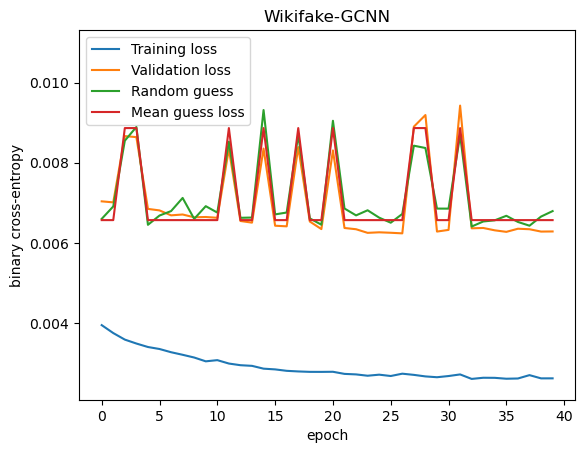

In [60]:
bottleneck = [4, 1/4, 1/4]
linear = [2, 1, 1, 1]
aggr = "mean"
skip = False
skip_linear = True
g = g_nuni_two_hop_dict_full_debug["g"]
num_neighbors = [8, 4]
batch_size = 1000
lr = 0.001
directed_msg = True
attention = True
batch_norm = True
epochs = 40


data_train_loader = pyg.loader.NeighborLoader(
    data=g,
    input_nodes=("data", g["data"].train_mask),
    num_neighbors=num_neighbors,
    batch_size=batch_size,
)
organization_train_loader = pyg.loader.NeighborLoader(
    data=g,
    input_nodes=("organization", g["organization"].train_mask),
    num_neighbors=num_neighbors,
    batch_size=batch_size,
)
person_train_loader = pyg.loader.NeighborLoader(
    data=g,
    input_nodes=("person", g["person"].train_mask),
    num_neighbors=num_neighbors,
    batch_size=batch_size,
)

data_validation_loader = pyg.loader.NeighborLoader(
    data=g,
    input_nodes=("data", g["data"].validation_mask),
    num_neighbors=num_neighbors,
    batch_size=batch_size,
)
organization_validation_loader = pyg.loader.NeighborLoader(
    data=g,
    input_nodes=("organization", g["organization"].validation_mask),
    num_neighbors=num_neighbors,
    batch_size=batch_size,
)
person_validation_loader = pyg.loader.NeighborLoader(
    data=g,
    input_nodes=("person", g["person"].validation_mask),
    num_neighbors=num_neighbors,
    batch_size=batch_size,
)

train_loaders = [
    data_train_loader,
    organization_train_loader,
    person_train_loader,
]
validation_loaders = [
    data_validation_loader,
    organization_validation_loader,
    person_validation_loader,
]
# with open("model", "rb") as f:
#     model = pickle.load(f)
model = pyg.nn.to_hetero(
    WikifakeCGNN(
        g,
        size_factor_series = bottleneck,  # [4, 4, 0.25, 0.25]
        skip = False,
        skip_linear= skip_linear,
        directed_msg = directed_msg,
        batch_norm = batch_norm, #batch_norm,
    ),
    g.metadata(),
    aggr=aggr,
).to(device)

optimizer = torch.optim.AdamW(model.parameters(), lr=lr)
_, validation_losses, epoch = train_validate_run(
    model,
    train_loaders,
    validation_loaders,
    optimizer,
    scaler,
    "Wikifake-GCNN",
    loss_weighing=None,
    early_stopping=False,
    g_dict=g_nuni_two_hop_dict,
    epochs=epochs,
    verbose=True,
)

final_validation_loss = validation_losses[-1]

## GNNExplainer

In [ ]:
class model_constrained_to_node_type(torch.nn.Module):
    def __init__(self, model, node_type):
        super().__init__()
        self.model = model
        self.node_type = node_type

    def forward(self, *args, **kwargs):
        return self.model(*args, **kwargs)[self.node_type]

    def __enter__(self):
        def new_forward(*args, **kwargs):
            return self.original_forward(*args, **kwargs)[self.node_type]
        self.model.forward = new_forward
        return self.model

    def __exit__(self, _exception_class, _exception_value, _traceback):
        self.model.forward = self.original_forward
        return False


class model_with_single_tensor_output(torch.nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, *args, **kwargs):
        return torch.cat([tensor for tensor in self.model(*args, **kwargs).values()])



@contextmanager
def constrain_model_to_node_type(model, node_type:str):
    orig_call = model.__call__
    def new_call(self, *args, **kwargs):
        return orig_call(*args, **kwargs)[node_type]
    model.__call__ = types.MethodType(new_call, model)
    try:
        yield
    finally:
        model.__call__ = orig_call

# model = rgcn
# with open("model", "rb") as f:
    # model = pickle.load(f)

explainer_model = model_with_single_tensor_output(model).to(device).eval()

explainer = Explainer(
    explainer_model,  # It is assumed that model outputs a single tensor.
    algorithm=GNNExplainer().to(device),
    explanation_type = 'model',
    node_mask_type = 'attributes',
    model_config = dict(
        mode='binary_classification',
        task_level='node',
        return_type='raw',
    ),
)
g = g.to(device)

hetero_explanation = explainer(
    g.x_dict,
    g.edge_index_dict,
    index=torch.tensor([1]),
)

explanations = []
i = 0
while len(explanations) < 10:
    ex = explainer(
            g.x_dict,
            g.edge_index_dict,
            index=torch.tensor([i]),
        )
    explanation_mask = {
        key: mask.sum(dim=-1) > 0
        for key, mask in ex.collect("node_mask", True).items()
    }
    subgraph = g.subgraph(explanation_mask).to("cpu")
    num_nodes = (
        subgraph['data'].num_nodes
        + subgraph['organization'].num_nodes
        + subgraph['person'].num_nodes
    )
    if num_nodes > 2 and num_nodes < 11:
        explanations.append(
            explainer(
                g.x_dict,
                g.edge_index_dict,
                index=torch.tensor([i]),
            )
        )
    i += 1

with open(in_data_dir("explanations"), "wb") as f:
    pickle.dump(explanations, f)

print(hetero_explanation)

### Create graph visualization functionality

This is source code from NetworkX with a tiny offset tweak!
https://networkx.org/documentation/stable/_modules/networkx/drawing/nx_pylab.html#draw_networkx_edge_labels

In [65]:
class FancyArrowFactory:
    """Draw arrows with `matplotlib.patches.FancyarrowPatch`"""

    class ConnectionStyleFactory:
        def __init__(self, connectionstyles, selfloop_height, ax=None):
            import matplotlib as mpl
            import matplotlib.path  # call as mpl.path
            import numpy as np

            self.ax = ax
            self.mpl = mpl
            self.np = np
            self.base_connection_styles = [
                mpl.patches.ConnectionStyle(cs) for cs in connectionstyles
            ]
            self.n = len(self.base_connection_styles)
            self.selfloop_height = selfloop_height

        def curved(self, edge_index):
            return self.base_connection_styles[edge_index % self.n]

        def self_loop(self, edge_index):
            def self_loop_connection(posA, posB, *args, **kwargs):
                if not self.np.all(posA == posB):
                    raise nx.NetworkXError(
                        "`self_loop` connection style method"
                        "is only to be used for self-loops"
                    )
                # this is called with _screen space_ values
                # so convert back to data space
                data_loc = self.ax.transData.inverted().transform(posA)
                v_shift = 0.1 * self.selfloop_height
                h_shift = v_shift * 0.5
                # put the top of the loop first so arrow is not hidden by node
                path = self.np.asarray(
                    [
                        # 1
                        [0, v_shift],
                        # 4 4 4
                        [h_shift, v_shift],
                        [h_shift, 0],
                        [0, 0],
                        # 4 4 4
                        [-h_shift, 0],
                        [-h_shift, v_shift],
                        [0, v_shift],
                    ]
                )
                # Rotate self loop 90 deg. if more than 1
                # This will allow for maximum of 4 visible self loops
                if edge_index % 4:
                    x, y = path.T
                    for _ in range(edge_index % 4):
                        x, y = y, -x
                    path = self.np.array([x, y]).T
                return self.mpl.path.Path(
                    self.ax.transData.transform(data_loc + path), [1, 4, 4, 4, 4, 4, 4]
                )

            return self_loop_connection

    def __init__(
        self,
        edge_pos,
        edgelist,
        nodelist,
        edge_indices,
        node_size,
        selfloop_height,
        connectionstyle="arc3",
        node_shape="o",
        arrowstyle="-",
        arrowsize=10,
        edge_color="k",
        alpha=None,
        linewidth=1.0,
        style="solid",
        min_source_margin=0,
        min_target_margin=0,
        ax=None,
    ):
        import matplotlib as mpl
        import matplotlib.patches  # call as mpl.patches
        import matplotlib.pyplot as plt
        import numpy as np

        if isinstance(connectionstyle, str):
            connectionstyle = [connectionstyle]
        elif np.iterable(connectionstyle):
            connectionstyle = list(connectionstyle)
        else:
            msg = "ConnectionStyleFactory arg `connectionstyle` must be str or iterable"
            raise nx.NetworkXError(msg)
        self.ax = ax
        self.mpl = mpl
        self.np = np
        self.edge_pos = edge_pos
        self.edgelist = edgelist
        self.nodelist = nodelist
        self.node_shape = node_shape
        self.min_source_margin = min_source_margin
        self.min_target_margin = min_target_margin
        self.edge_indices = edge_indices
        self.node_size = node_size
        self.connectionstyle_factory = self.ConnectionStyleFactory(
            connectionstyle, selfloop_height, ax
        )
        self.arrowstyle = arrowstyle
        self.arrowsize = arrowsize
        self.arrow_colors = mpl.colors.colorConverter.to_rgba_array(edge_color, alpha)
        self.linewidth = linewidth
        self.style = style
        if isinstance(arrowsize, list) and len(arrowsize) != len(edge_pos):
            raise ValueError("arrowsize should have the same length as edgelist")

    def __call__(self, i):
        (x1, y1), (x2, y2) = self.edge_pos[i]
        shrink_source = 0  # space from source to tail
        shrink_target = 0  # space from  head to target
        if (
            self.np.iterable(self.min_source_margin)
            and not isinstance(self.min_source_margin, str)
            and not isinstance(self.min_source_margin, tuple)
        ):
            min_source_margin = self.min_source_margin[i]
        else:
            min_source_margin = self.min_source_margin

        if (
            self.np.iterable(self.min_target_margin)
            and not isinstance(self.min_target_margin, str)
            and not isinstance(self.min_target_margin, tuple)
        ):
            min_target_margin = self.min_target_margin[i]
        else:
            min_target_margin = self.min_target_margin

        if self.np.iterable(self.node_size):  # many node sizes
            source, target = self.edgelist[i][:2]
            source_node_size = self.node_size[self.nodelist.index(source)]
            target_node_size = self.node_size[self.nodelist.index(target)]
            shrink_source = self.to_marker_edge(source_node_size, self.node_shape)
            shrink_target = self.to_marker_edge(target_node_size, self.node_shape)
        else:
            shrink_source = self.to_marker_edge(self.node_size, self.node_shape)
            shrink_target = shrink_source
        shrink_source = max(shrink_source, min_source_margin)
        shrink_target = max(shrink_target, min_target_margin)

        # scale factor of arrow head
        if isinstance(self.arrowsize, list):
            mutation_scale = self.arrowsize[i]
        else:
            mutation_scale = self.arrowsize

        if len(self.arrow_colors) > i:
            arrow_color = self.arrow_colors[i]
        elif len(self.arrow_colors) == 1:
            arrow_color = self.arrow_colors[0]
        else:  # Cycle through colors
            arrow_color = self.arrow_colors[i % len(self.arrow_colors)]

        if self.np.iterable(self.linewidth):
            if len(self.linewidth) > i:
                linewidth = self.linewidth[i]
            else:
                linewidth = self.linewidth[i % len(self.linewidth)]
        else:
            linewidth = self.linewidth

        if (
            self.np.iterable(self.style)
            and not isinstance(self.style, str)
            and not isinstance(self.style, tuple)
        ):
            if len(self.style) > i:
                linestyle = self.style[i]
            else:  # Cycle through styles
                linestyle = self.style[i % len(self.style)]
        else:
            linestyle = self.style

        if x1 == x2 and y1 == y2:
            connectionstyle = self.connectionstyle_factory.self_loop(
                self.edge_indices[i]
            )
        else:
            connectionstyle = self.connectionstyle_factory.curved(self.edge_indices[i])

        if (
            self.np.iterable(self.arrowstyle)
            and not isinstance(self.arrowstyle, str)
            and not isinstance(self.arrowstyle, tuple)
        ):
            arrowstyle = self.arrowstyle[i]
        else:
            arrowstyle = self.arrowstyle

        return self.mpl.patches.FancyArrowPatch(
            (x1, y1),
            (x2, y2),
            arrowstyle=arrowstyle,
            shrinkA=shrink_source,
            shrinkB=shrink_target,
            mutation_scale=mutation_scale,
            color=arrow_color,
            linewidth=linewidth,
            connectionstyle=connectionstyle,
            linestyle=linestyle,
            zorder=1,  # arrows go behind nodes
        )

    def to_marker_edge(self, marker_size, marker):
        if marker in "s^>v<d":  # `large` markers need extra space
            return self.np.sqrt(2 * marker_size) / 2
        else:
            return self.np.sqrt(marker_size) / 2



def draw_networkx_edge_labels_with_offsets(
    G,
    pos,
    edge_labels=None,
    label_pos=0.5,
    font_size=10,
    font_color="k",
    font_family="sans-serif",
    font_weight="normal",
    alpha=None,
    bbox=None,
    horizontalalignment="center",
    verticalalignment="center",
    ax=None,
    rotate=True,
    clip_on=True,
    node_size=300,
    nodelist=None,
    connectionstyle="arc3",
    hide_ticks=True,
    offsets=None,
):
    """Draw edge labels.

    Parameters
    ----------
    G : graph
        A networkx graph

    pos : dictionary
        A dictionary with nodes as keys and positions as values.
        Positions should be sequences of length 2.

    edge_labels : dictionary (default=None)
        Edge labels in a dictionary of labels keyed by edge two-tuple.
        Only labels for the keys in the dictionary are drawn.

    label_pos : float (default=0.5)
        Position of edge label along edge (0=head, 0.5=center, 1=tail)

    font_size : int (default=10)
        Font size for text labels

    font_color : color (default='k' black)
        Font color string. Color can be string or rgb (or rgba) tuple of
        floats from 0-1.

    font_weight : string (default='normal')
        Font weight

    font_family : string (default='sans-serif')
        Font family

    alpha : float or None (default=None)
        The text transparency

    bbox : Matplotlib bbox, optional
        Specify text box properties (e.g. shape, color etc.) for edge labels.
        Default is {boxstyle='round', ec=(1.0, 1.0, 1.0), fc=(1.0, 1.0, 1.0)}.

    horizontalalignment : string (default='center')
        Horizontal alignment {'center', 'right', 'left'}

    verticalalignment : string (default='center')
        Vertical alignment {'center', 'top', 'bottom', 'baseline', 'center_baseline'}

    ax : Matplotlib Axes object, optional
        Draw the graph in the specified Matplotlib axes.

    rotate : bool (default=True)
        Rotate edge labels to lie parallel to edges

    clip_on : bool (default=True)
        Turn on clipping of edge labels at axis boundaries

    node_size : scalar or array (default=300)
        Size of nodes.  If an array it must be the same length as nodelist.

    nodelist : list, optional (default=G.nodes())
       This provides the node order for the `node_size` array (if it is an array).

    connectionstyle : string or iterable of strings (default="arc3")
        Pass the connectionstyle parameter to create curved arc of rounding
        radius rad. For example, connectionstyle='arc3,rad=0.2'.
        See `matplotlib.patches.ConnectionStyle` and
        `matplotlib.patches.FancyArrowPatch` for more info.
        If Iterable, index indicates i'th edge key of MultiGraph

    hide_ticks : bool, optional
        Hide ticks of axes. When `True` (the default), ticks and ticklabels
        are removed from the axes. To set ticks and tick labels to the pyplot default,
        use ``hide_ticks=False``.

    Returns
    -------
    dict
        `dict` of labels keyed by edge

    Examples
    --------
    >>> G = nx.dodecahedral_graph()
    >>> edge_labels = nx.draw_networkx_edge_labels(G, pos=nx.spring_layout(G))

    Also see the NetworkX drawing examples at
    https://networkx.org/documentation/latest/auto_examples/index.html

    See Also
    --------
    draw
    draw_networkx
    draw_networkx_nodes
    draw_networkx_edges
    draw_networkx_labels
    """
    import matplotlib as mpl
    # import matplotlib.pyplot as plt
    # import numpy as np

    class CurvedArrowText(mpl.text.Text):
        def __init__(
            self,
            arrow,
            *args,
            label_pos=0.5,
            labels_horizontal=False,
            ax=None,
            **kwargs,
        ):
            # Bind to FancyArrowPatch
            self.arrow = arrow
            # how far along the text should be on the curve,
            # 0 is at start, 1 is at end etc.
            self.label_pos = label_pos
            self.labels_horizontal = labels_horizontal
            if ax is None:
                ax = plt.gca()
            self.ax = ax
            self.x, self.y, self.angle = self._update_text_pos_angle(arrow)

            # Create text object
            super().__init__(self.x, self.y, *args, rotation=self.angle, **kwargs)
            # Bind to axis
            self.ax.add_artist(self)

        def _get_arrow_path_disp(self, arrow):
            """
            This is part of FancyArrowPatch._get_path_in_displaycoord
            It omits the second part of the method where path is converted
                to polygon based on width
            The transform is taken from ax, not the object, as the object
                has not been added yet, and doesn't have transform
            """
            dpi_cor = arrow._dpi_cor
            trans_data = self.ax.transData
            if arrow._posA_posB is None:
                raise ValueError(
                    "Can only draw labels for fancy arrows with "
                    "posA and posB inputs, not custom path"
                )
            posA = arrow._convert_xy_units(arrow._posA_posB[0])
            posB = arrow._convert_xy_units(arrow._posA_posB[1])
            (posA, posB) = trans_data.transform((posA, posB))
            _path = arrow.get_connectionstyle()(
                posA,
                posB,
                patchA=arrow.patchA,
                patchB=arrow.patchB,
                shrinkA=arrow.shrinkA * dpi_cor,
                shrinkB=arrow.shrinkB * dpi_cor,
            )
            # Return is in display coordinates
            return _path

        def _update_text_pos_angle(self, arrow):
            # Fractional label position
            # Text position at a proportion t along the line in display coords
            # default is 0.5 so text appears at the halfway point
            t = self.label_pos
            tt = 1 - t
            path_disp = self._get_arrow_path_disp(arrow)
            is_bar_style = isinstance(
                arrow.get_connectionstyle(), mpl.patches.ConnectionStyle.Bar
            )
            # 1. Calculate x and y
            if is_bar_style:
                # Bar Connection Style - straight line
                _, (cx1, cy1), (cx2, cy2), _ = path_disp.vertices
                x = cx1 * tt + cx2 * t
                y = cy1 * tt + cy2 * t
            else:
                # Arc or Angle type Connection Styles - Bezier curve
                (x1, y1), (cx, cy), (x2, y2) = path_disp.vertices
                x = tt**2 * x1 + 2 * t * tt * cx + t**2 * x2
                y = tt**2 * y1 + 2 * t * tt * cy + t**2 * y2
            # 2. Calculate Angle
            if self.labels_horizontal:
                # Horizontal text labels
                angle = 0
            else:
                # Labels parallel to curve
                if is_bar_style:
                    change_x = (cx2 - cx1) / 2
                    change_y = (cy2 - cy1) / 2
                else:
                    change_x = 2 * tt * (cx - x1) + 2 * t * (x2 - cx)
                    change_y = 2 * tt * (cy - y1) + 2 * t * (y2 - cy)
                angle = np.arctan2(change_y, change_x) / (2 * np.pi) * 360
                # Text is "right way up"
                if angle > 90:
                    angle -= 180
                elif angle < -90:
                    angle += 180
            (x, y) = self.ax.transData.inverted().transform((x, y))
            return x, y, angle

        def draw(self, renderer):
            # recalculate the text position and angle
            self.x, self.y, self.angle = self._update_text_pos_angle(self.arrow)
            self.set_position((self.x, self.y))
            self.set_rotation(self.angle)
            # redraw text
            super().draw(renderer)

    # use default box of white with white border
    if bbox is None:
        bbox = {"boxstyle": "round", "ec": (1.0, 1.0, 1.0), "fc": (1.0, 1.0, 1.0)}

    if isinstance(connectionstyle, str):
        connectionstyle = [connectionstyle]
    elif np.iterable(connectionstyle):
        connectionstyle = list(connectionstyle)
    else:
        raise nx.NetworkXError(
            "draw_networkx_edges arg `connectionstyle` must be"
            "string or iterable of strings"
        )

    if ax is None:
        ax = plt.gca()

    if edge_labels is None:
        kwds = {"keys": True} if G.is_multigraph() else {}
        edge_labels = {tuple(edge): d for *edge, d in G.edges(data=True, **kwds)}
    # NOTHING TO PLOT
    if not edge_labels:
        return {}
    edgelist, labels = zip(*edge_labels.items())

    if nodelist is None:
        nodelist = list(G.nodes())

    # set edge positions
    ####################################################################
    ####   THIS IS THE TWEAK
    ####################################################################
    # original
    # edge_pos = np.asarray([(pos[e[0]], pos[e[1]]) for e in edgelist])
    if offsets is not None:
        edge_pos = np.asarray([(pos[e[0]] + offsets[i], pos[e[1]] + offsets[i]) for i, e in enumerate(edgelist)])
    else:
        edge_pos = np.asarray([(pos[e[0]], pos[e[1]]) for e in edgelist])
    # edge_pos = []
    # for i, e in enumerate(edgelist):
    #     if i % 2 == 0:
    #         edge_pos.append((pos[e[0]] + offsets[i], pos[e[1]]))
    #     else:
    #         edge_pos.append((pos[e[0]], pos[e[1]] + offsets[i]))
    # edge_pos = np.array(edge_pos)
    ####################################################################
    ####
    ####################################################################

    if G.is_multigraph():
        key_count = collections.defaultdict(lambda: itertools.count(0))
        edge_indices = [next(key_count[tuple(e[:2])]) for e in edgelist]
    else:
        edge_indices = [0] * len(edgelist)

    # Used to determine self loop mid-point
    # Note, that this will not be accurate,
    #   if not drawing edge_labels for all edges drawn
    h = 0
    if edge_labels:
        miny = np.amin(np.ravel(edge_pos[:, :, 1]))
        maxy = np.amax(np.ravel(edge_pos[:, :, 1]))
        h = maxy - miny
    selfloop_height = h if h != 0 else 0.005 * np.array(node_size).max()
    fancy_arrow_factory = FancyArrowFactory(
        edge_pos,
        edgelist,
        nodelist,
        edge_indices,
        node_size,
        selfloop_height,
        connectionstyle,
        ax=ax,
    )

    individual_params = {}

    def check_individual_params(p_value, p_name):
        # TODO should this be list or array (as in a numpy array)?
        if isinstance(p_value, list):
            if len(p_value) != len(edgelist):
                raise ValueError(f"{p_name} must have the same length as edgelist.")
            individual_params[p_name] = p_value.iter()

    # Don't need to pass in an edge because these are lists, not dicts
    def get_param_value(p_value, p_name):
        if p_name in individual_params:
            return next(individual_params[p_name])
        return p_value

    check_individual_params(font_size, "font_size")
    check_individual_params(font_color, "font_color")
    check_individual_params(font_weight, "font_weight")
    check_individual_params(alpha, "alpha")
    check_individual_params(horizontalalignment, "horizontalalignment")
    check_individual_params(verticalalignment, "verticalalignment")
    check_individual_params(rotate, "rotate")
    check_individual_params(label_pos, "label_pos")

    text_items = {}
    for i, (edge, label) in enumerate(zip(edgelist, labels)):
        if not isinstance(label, str):
            label = str(label)  # this makes "1" and 1 labeled the same

        n1, n2 = edge[:2]
        arrow = fancy_arrow_factory(i)
        if n1 == n2:
            connectionstyle_obj = arrow.get_connectionstyle()
            posA = ax.transData.transform(pos[n1])
            path_disp = connectionstyle_obj(posA, posA)
            path_data = ax.transData.inverted().transform_path(path_disp)
            x, y = path_data.vertices[0]
            text_items[edge] = ax.text(
                x,
                y,
                label,
                size=get_param_value(font_size, "font_size"),
                color=get_param_value(font_color, "font_color"),
                family=get_param_value(font_family, "font_family"),
                weight=get_param_value(font_weight, "font_weight"),
                alpha=get_param_value(alpha, "alpha"),
                horizontalalignment=get_param_value(
                    horizontalalignment, "horizontalalignment"
                ),
                verticalalignment=get_param_value(
                    verticalalignment, "verticalalignment"
                ),
                rotation=0,
                transform=ax.transData,
                bbox=bbox,
                zorder=1,
                clip_on=clip_on,
            )
        else:
            text_items[edge] = CurvedArrowText(
                arrow,
                label,
                size=get_param_value(font_size, "font_size"),
                color=get_param_value(font_color, "font_color"),
                family=get_param_value(font_family, "font_family"),
                weight=get_param_value(font_weight, "font_weight"),
                alpha=get_param_value(alpha, "alpha"),
                horizontalalignment=get_param_value(
                    horizontalalignment, "horizontalalignment"
                ),
                verticalalignment=get_param_value(
                    verticalalignment, "verticalalignment"
                ),
                transform=ax.transData,
                bbox=bbox,
                zorder=1,
                clip_on=clip_on,
                label_pos=get_param_value(label_pos, "label_pos"),
                labels_horizontal=not get_param_value(rotate, "rotate"),
                ax=ax,
            )

    if hide_ticks:
        ax.tick_params(
            axis="both",
            which="both",
            bottom=False,
            left=False,
            labelbottom=False,
            labelleft=False,
        )

    return text_items

[array(['Tohoku University', 'Tohoku Medical Megabank Organization',
       'Tohoku University Repository'], dtype=object), array(['Daisuke Miyata', 'William Tongamp', 'Masaru Kubo', 'Wei Jiao',
       'Junjie Li'], dtype=object)]
['Tohoku University' 'Tohoku Medical Megabank Organization'
 'Tohoku University Repository' 'Daisuke Miyata' 'William Tongamp'
 'Masaru Kubo' 'Wei Jiao' 'Junjie Li']


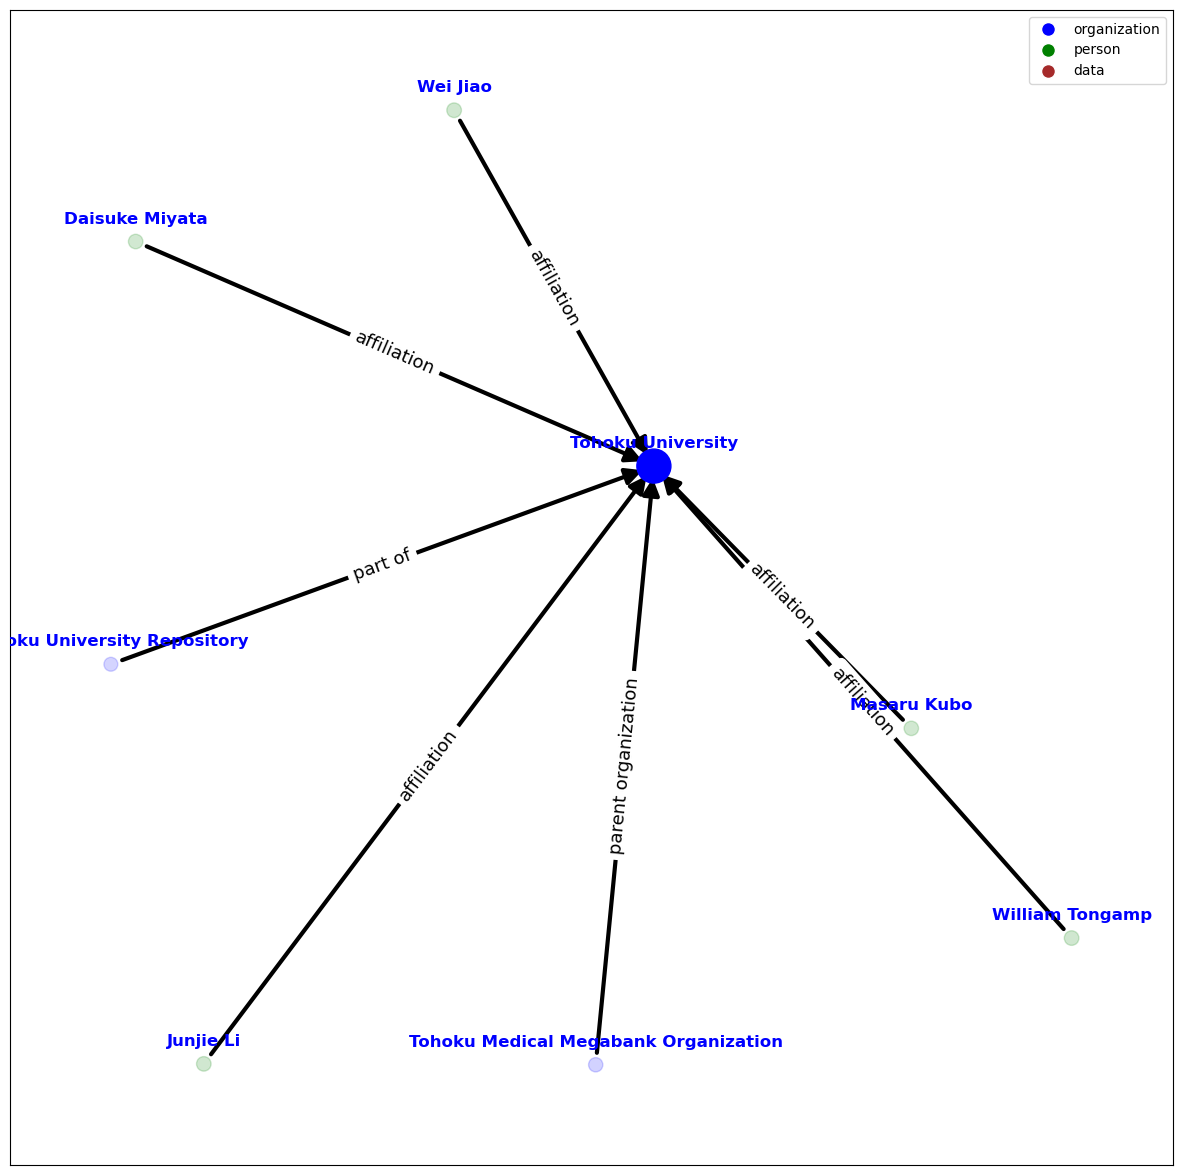

0
[array(['Frankfurter Allgemeine Zeitung'], dtype='<U30'), array(['Gerald Braunberger', 'Patrick Bernau', 'Carsten Knop',
       'Sven Astheimer'], dtype=object)]
['Frankfurter Allgemeine Zeitung' 'Gerald Braunberger' 'Patrick Bernau'
 'Carsten Knop' 'Sven Astheimer']


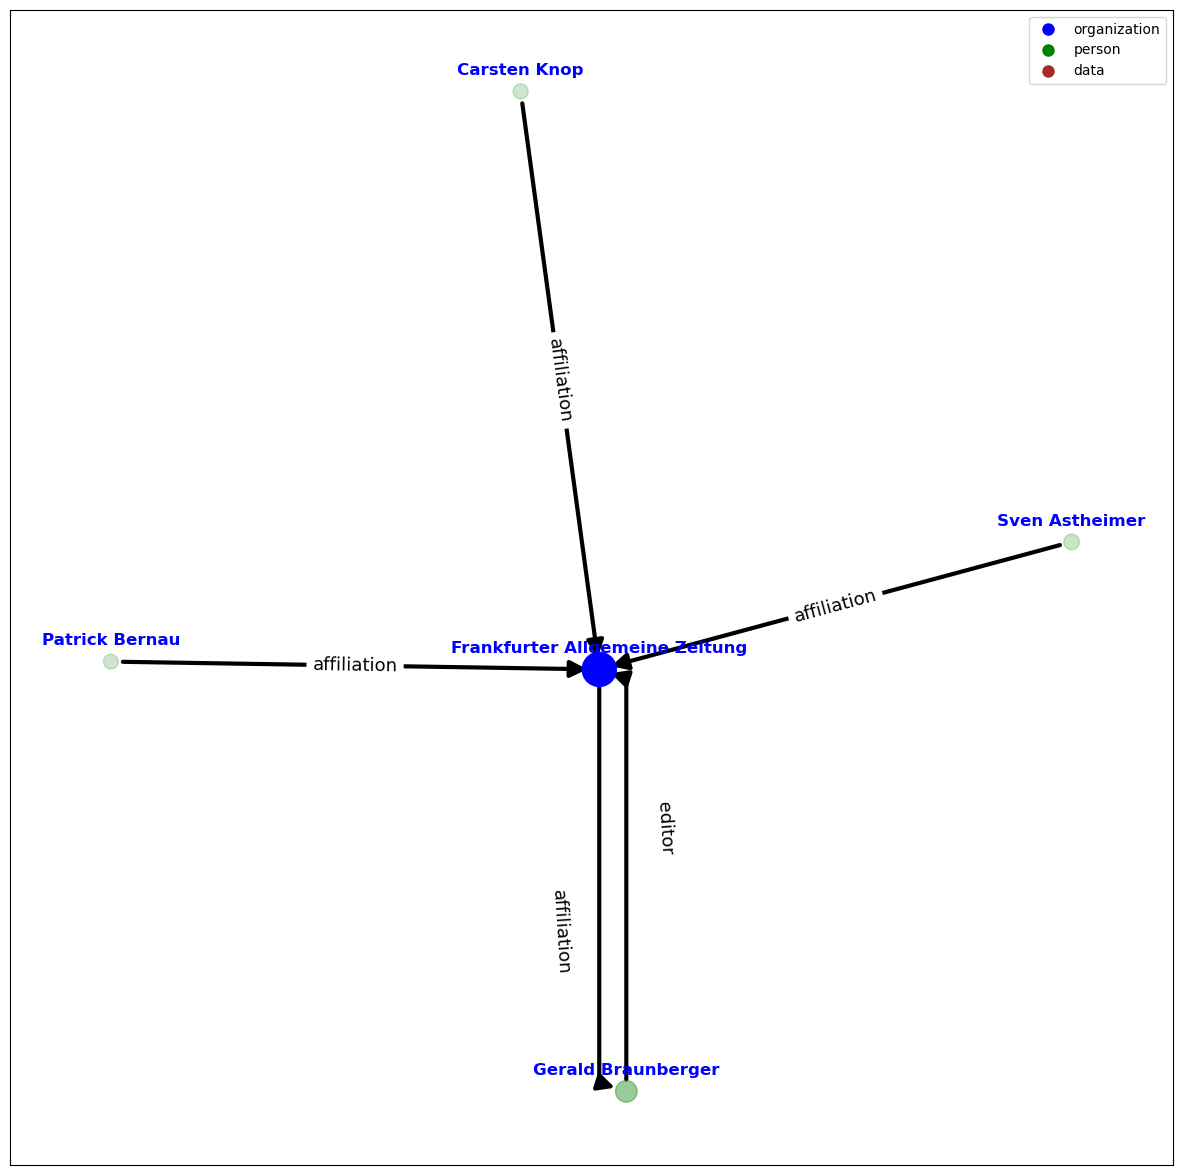

1
[array(['Indian National Congress',
       'Unorganised Workers and Employees Congress',
       'Rajasthan Pradesh Congress Committee',
       'All India Congress Committee', 'Congress Working Committee'],
      dtype=object), array(['Puran Singh Azad'], dtype='<U16')]
['Indian National Congress' 'Unorganised Workers and Employees Congress'
 'Rajasthan Pradesh Congress Committee' 'All India Congress Committee'
 'Congress Working Committee' 'Puran Singh Azad']


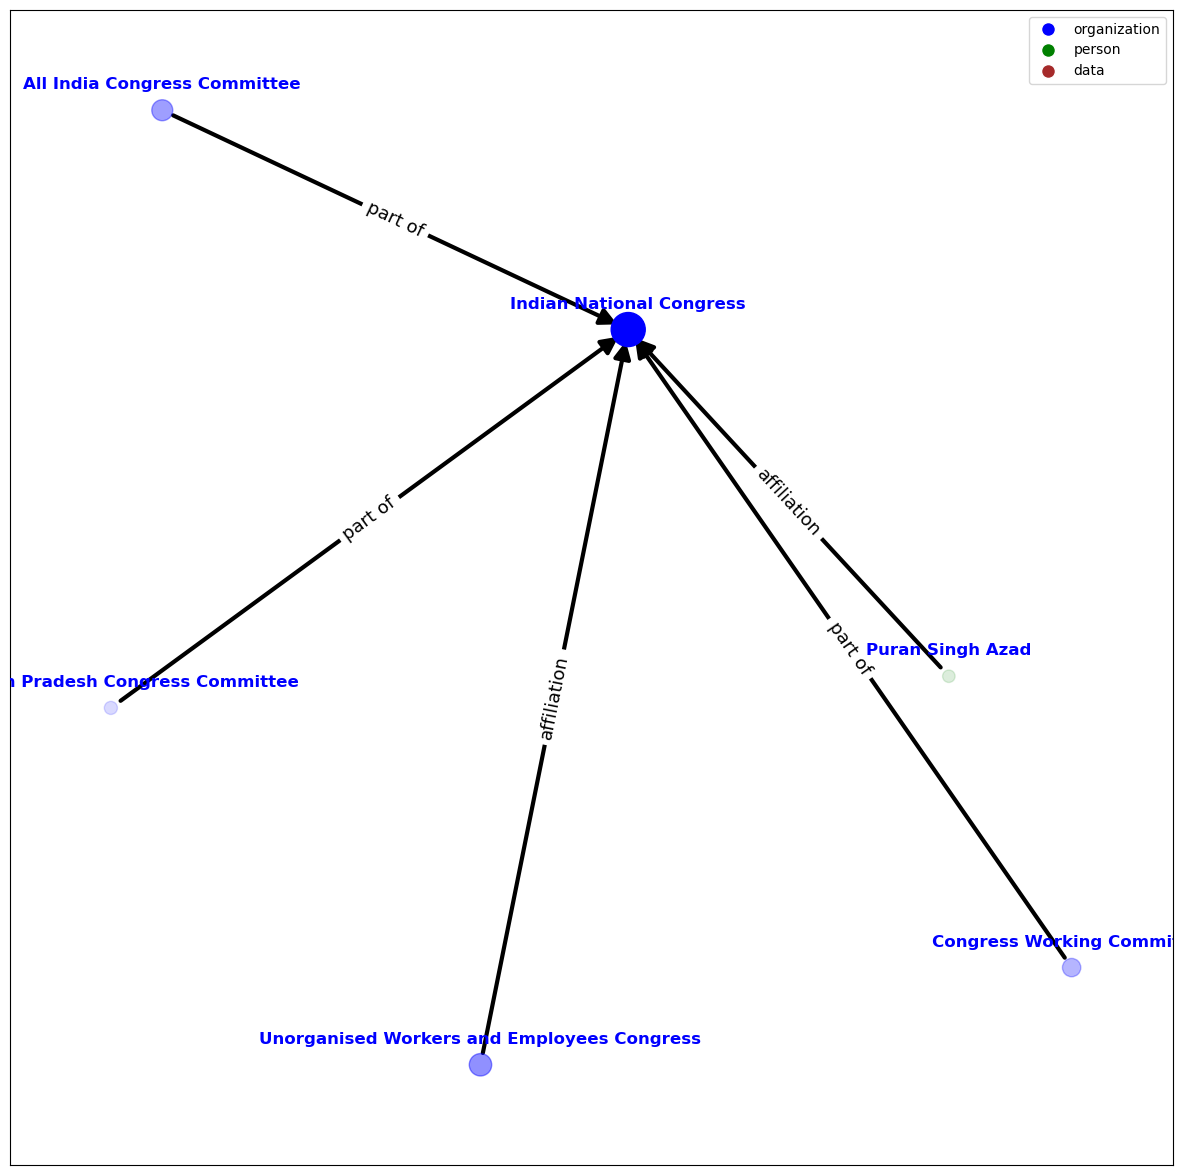

2
[array(['Cardiff University', 'Special Collections and Archives',
       "Children's Hospital for Wales",
       'Google News Initiative University Network', 'Whitchurch Hospital',
       'Cardiff University Archives', 'Wales Governance Centre'],
      dtype=object)]
['Cardiff University' 'Special Collections and Archives'
 "Children's Hospital for Wales"
 'Google News Initiative University Network' 'Whitchurch Hospital'
 'Cardiff University Archives' 'Wales Governance Centre']


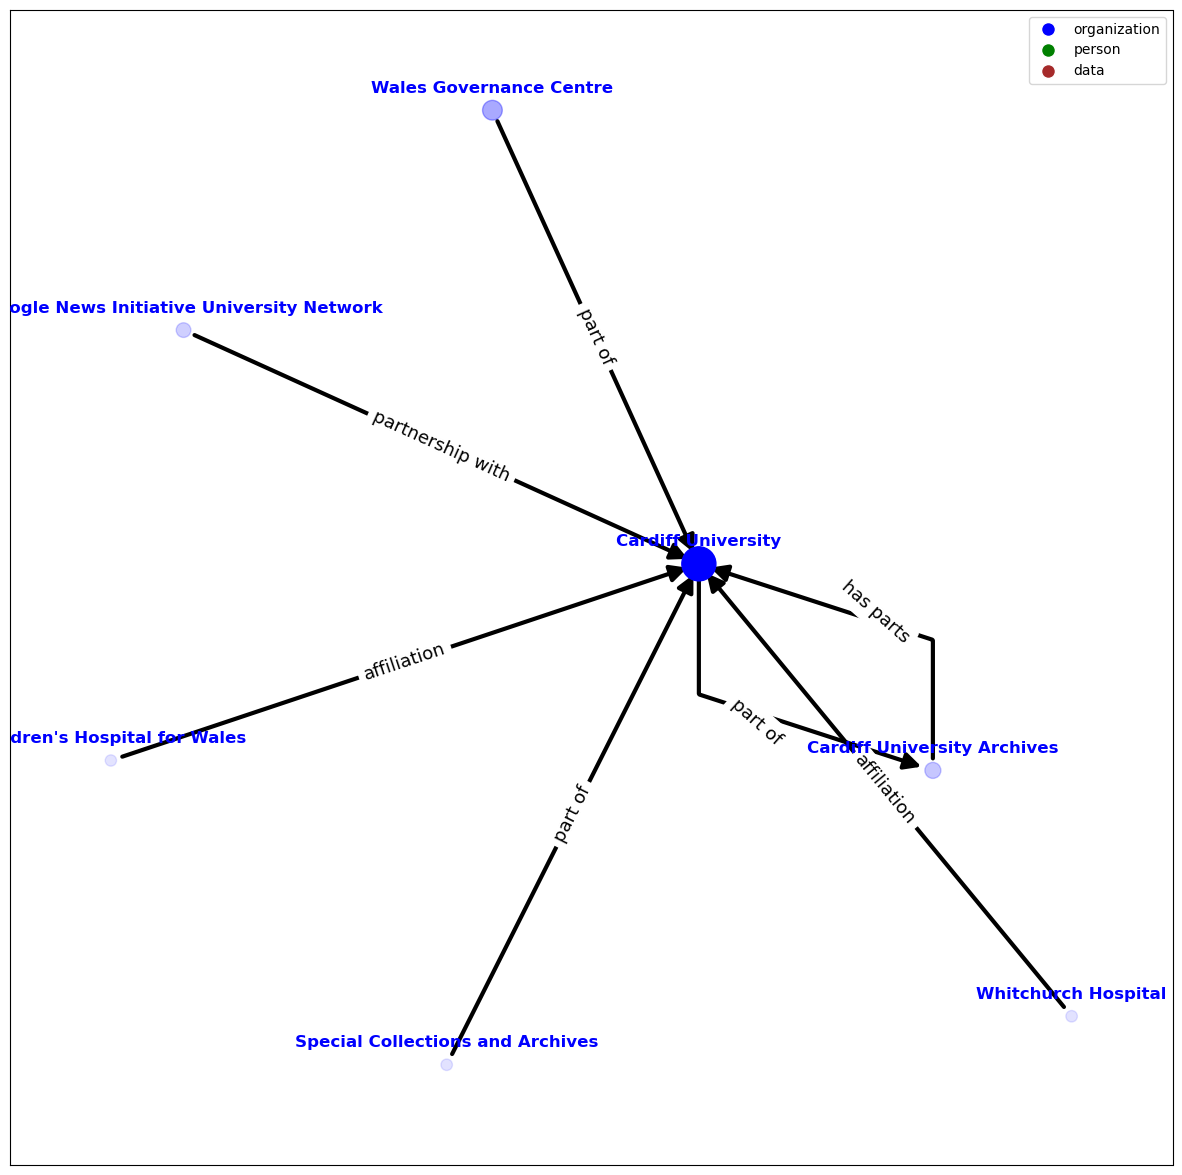

3
[array(['Case Western Reserve University',
       'Data Processing and Analysis Consortium',
       'Association of Independent Technological Universities',
       'Cleveland Institute of Music',
       "Rainbow Babies & Children's Hospital", 'Robinson Music Library',
       'California Institute of Technology', 'Carnegie Mellon University',
       'Rochester Institute of Technology',
       'Rose–Hulman Institute of Technology',
       'Embry–Riddle Aeronautical University',
       'Rensselaer Polytechnic Institute', 'Drexel University',
       'Lawrence Technological University'], dtype=object)]
['Case Western Reserve University'
 'Data Processing and Analysis Consortium'
 'Association of Independent Technological Universities'
 'Cleveland Institute of Music' "Rainbow Babies & Children's Hospital"
 'Robinson Music Library' 'California Institute of Technology'
 'Carnegie Mellon University' 'Rochester Institute of Technology'
 'Rose–Hulman Institute of Technology'
 'Embry–Riddle Aero

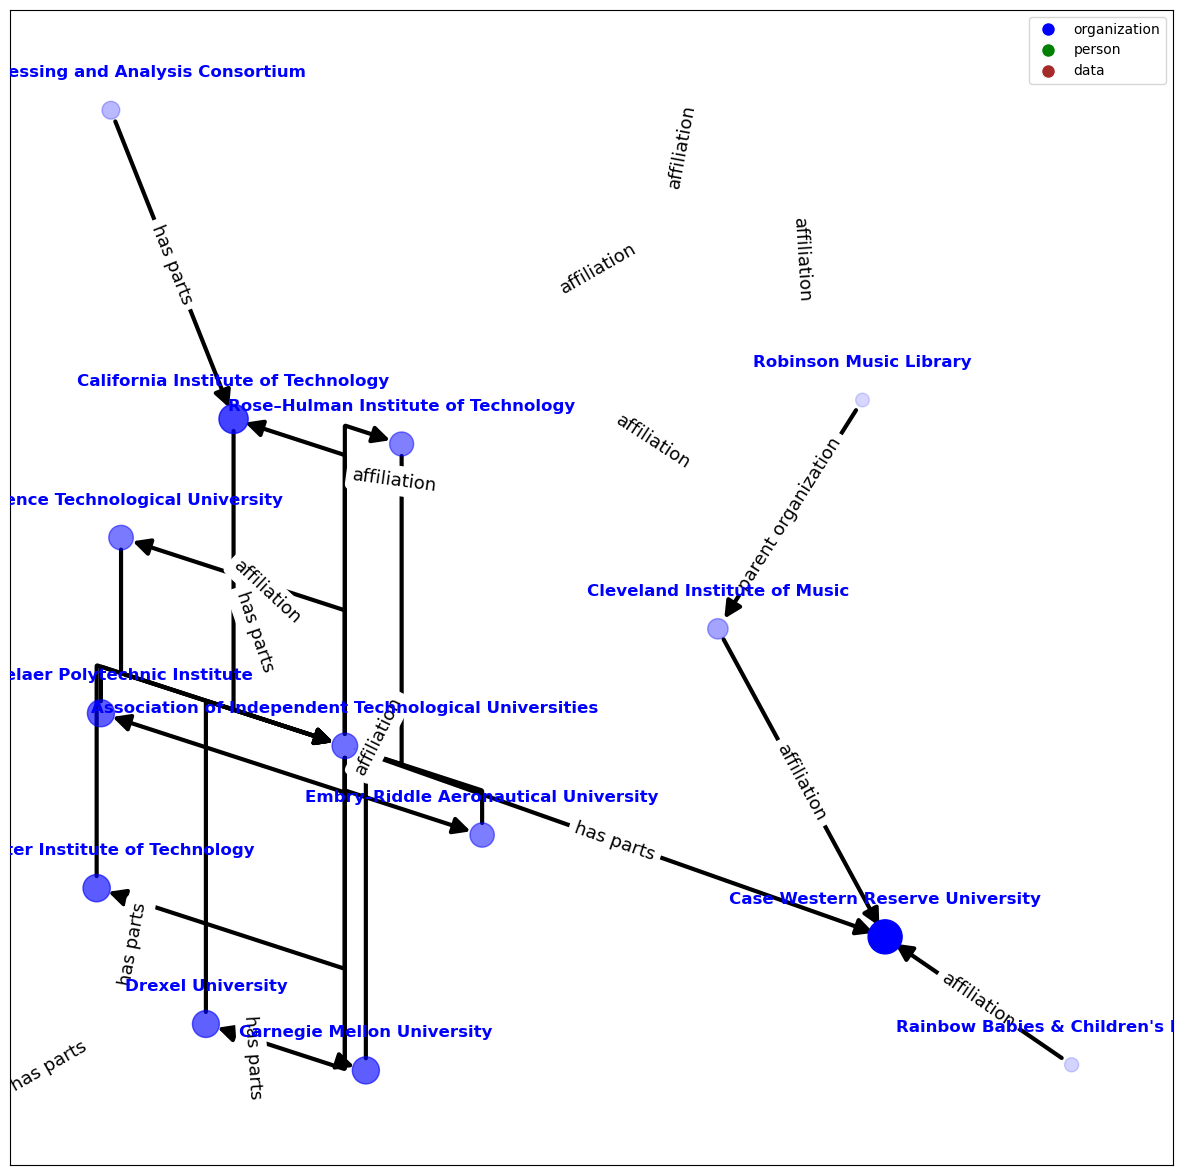

4
[array(['University of Waterloo', 'University of Waterloo Library',
       'Special Collections & Archives'], dtype=object)]
['University of Waterloo' 'University of Waterloo Library'
 'Special Collections & Archives']


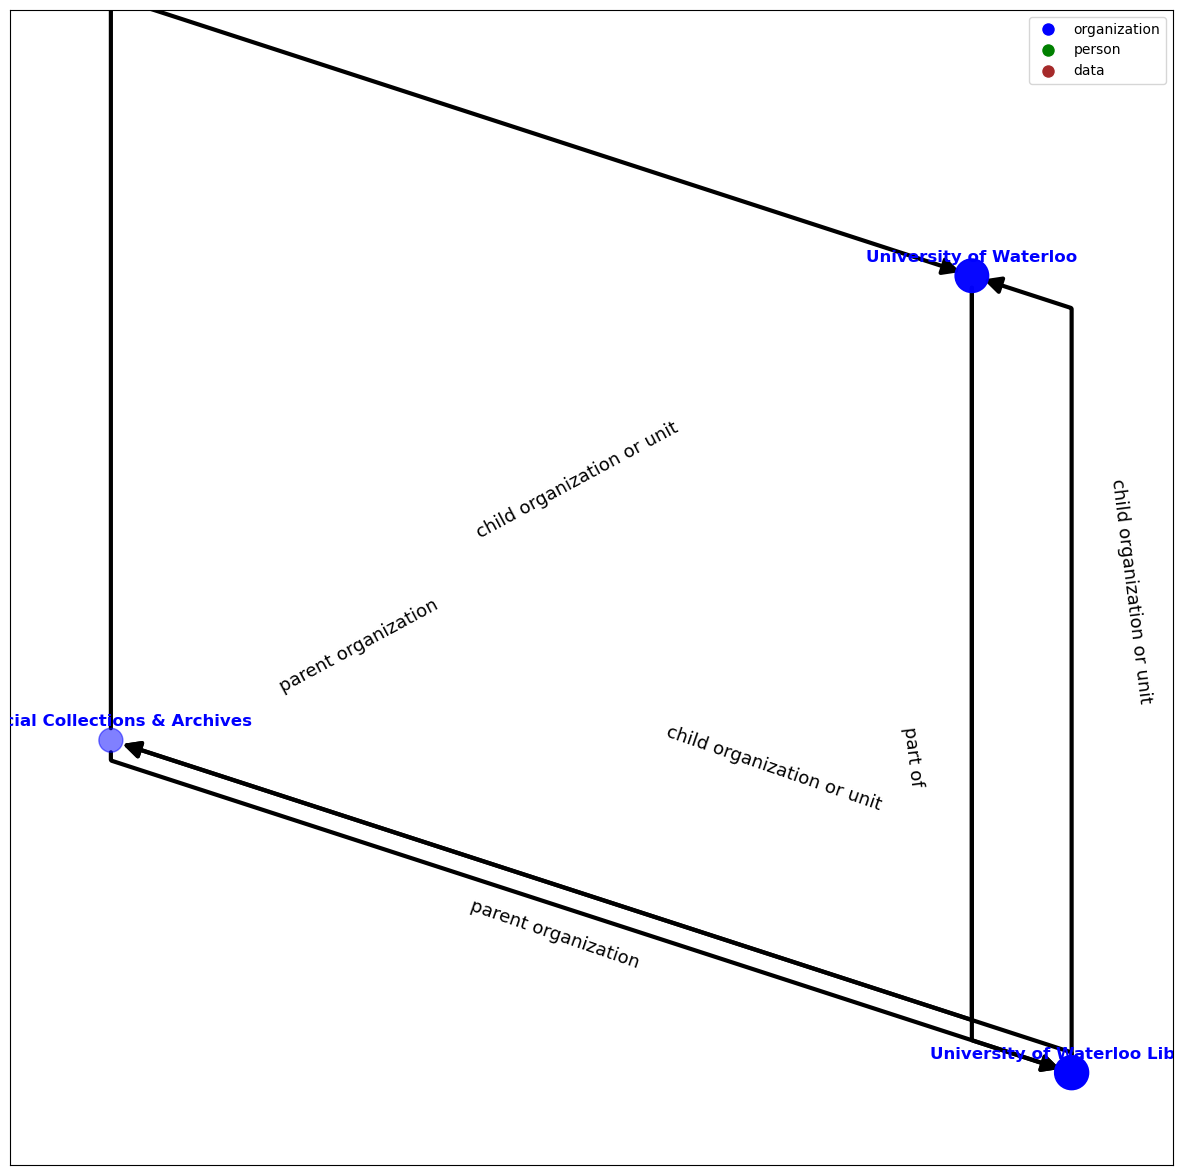

5
[array(['Cato Institute', 'Fraser Institute', 'Atlas Network',
       'Warsaw Enterprise Institute', 'Institut Ostrom Catalunya',
       'Centre for Public Policy Research',
       'Institut de recherches économiques et fiscales',
       'Institut économique de Paris', 'Macdonald-Laurier Institute'],
      dtype=object)]
['Cato Institute' 'Fraser Institute' 'Atlas Network'
 'Warsaw Enterprise Institute' 'Institut Ostrom Catalunya'
 'Centre for Public Policy Research'
 'Institut de recherches économiques et fiscales'
 'Institut économique de Paris' 'Macdonald-Laurier Institute']


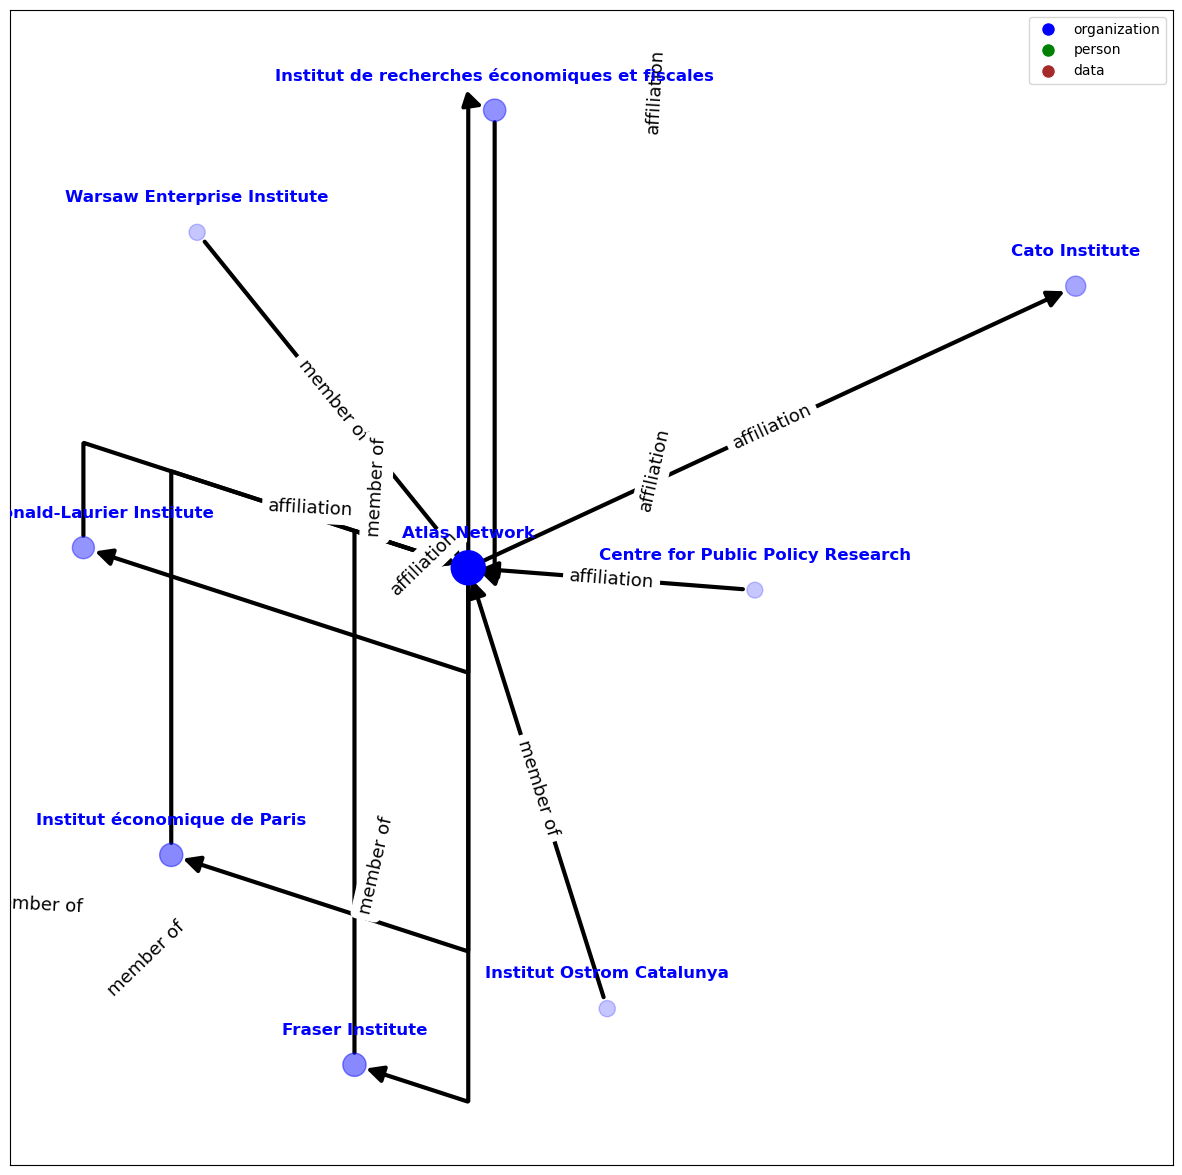

6
[array(['Rotten Tomatoes', 'NBC', 'KARE', 'KOMU-TV', 'KNBC', 'WNBC', 'KGW',
       'KING-TV', 'KPNX', 'WJAC-TV', 'NBCSN', 'WCAU', 'WCNC-TV',
       'WDIV-TV', 'WFMJ-TV', 'WIS', 'WMAQ-TV', 'WPTZ', 'WSMV-TV', 'WKYC',
       'WTVJ', 'KGET-TV', 'KAGS-LD', 'KALB-TV', 'KAMR-TV', 'KCEN-TV',
       'KCWY-DT', 'KOBI', 'KSBW', 'KSBY', 'KSL-TV', 'KSNK', 'KVLY-TV',
       'Motion Picture Association', 'NBCUniversal', 'WBBH-TV', 'WECT',
       'WFLA-TV', 'WNJU', 'WOWT', 'WPMI-TV', 'WRC-TV', 'WSAZ-TV', 'WSVN',
       'WVIT', 'E!', 'NBC Universal Global Networks España',
       'Universal Television', 'Telemundo', 'Universal Pictures',
       'Universal TV', 'Q2745022', 'WHFV', 'WBRE-TV', 'WMGM-TV',
       'Universal Studios Home Entertainment', 'Q6061245', 'KNPG-LD',
       'K17FA-D', 'KARK-TV', 'KATH-LD', 'KVFD-TV', 'KVZK-2', 'KidsCo',
       'WNYT', 'WVGN-LD', 'Movies 24', 'WKAQ-TV', 'Illumination',
       'KKEY-LD', 'KVTX-LD', 'Working Title Films', 'KXNU-CD', 'KJWY-LD',
       'KJNK-LD', 'KESE

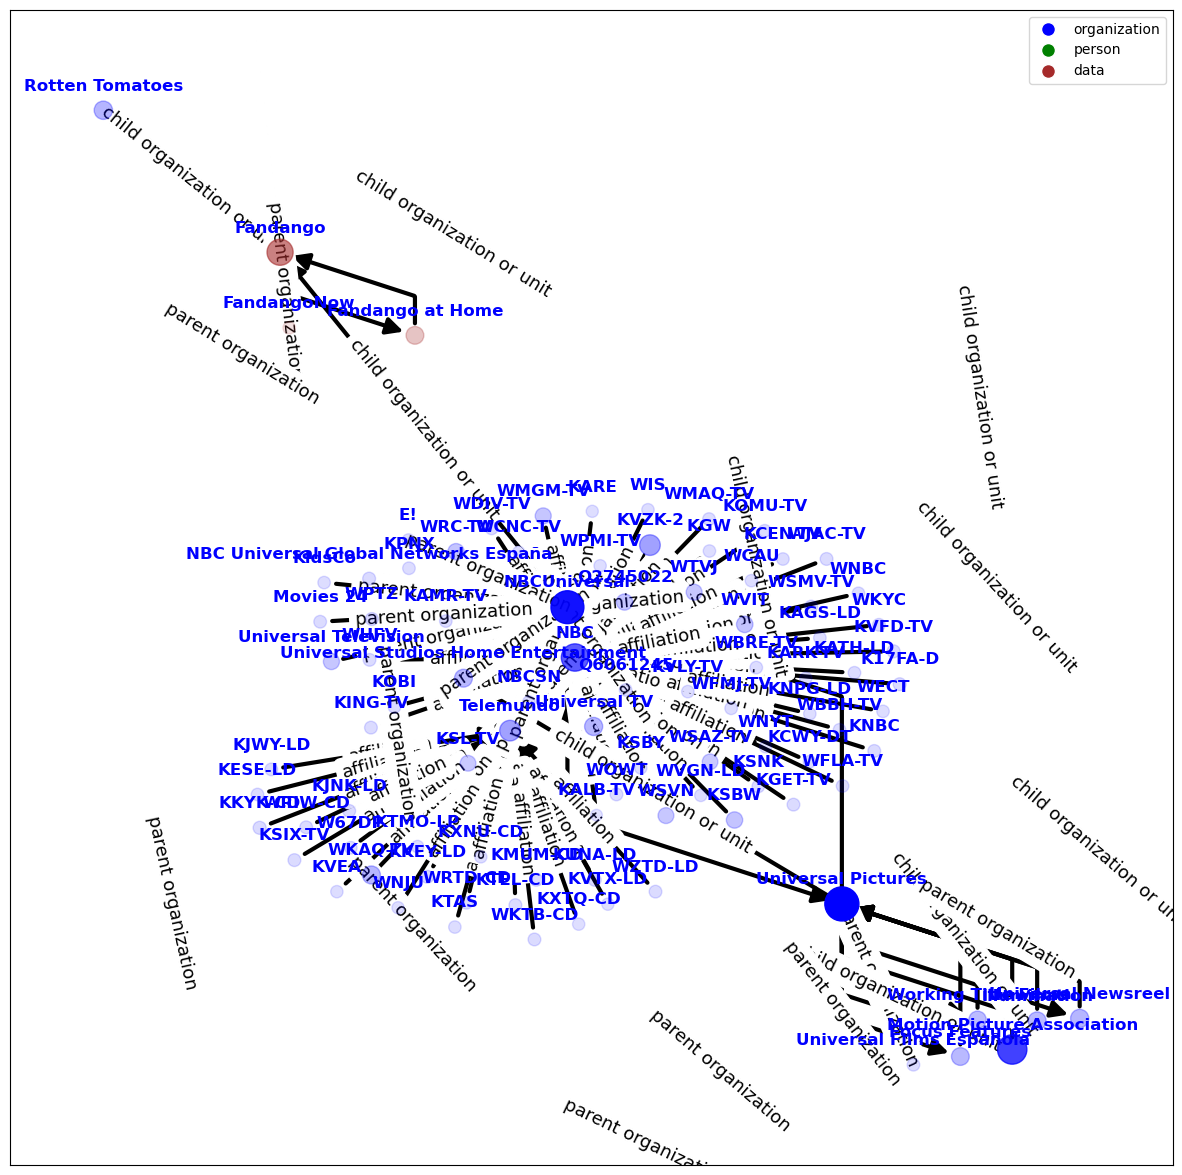

7
[array(['Live Nation Entertainment', 'Ticketmaster', 'Roc Nation',
       'Live Nation UK'], dtype=object)]
['Live Nation Entertainment' 'Ticketmaster' 'Roc Nation' 'Live Nation UK']


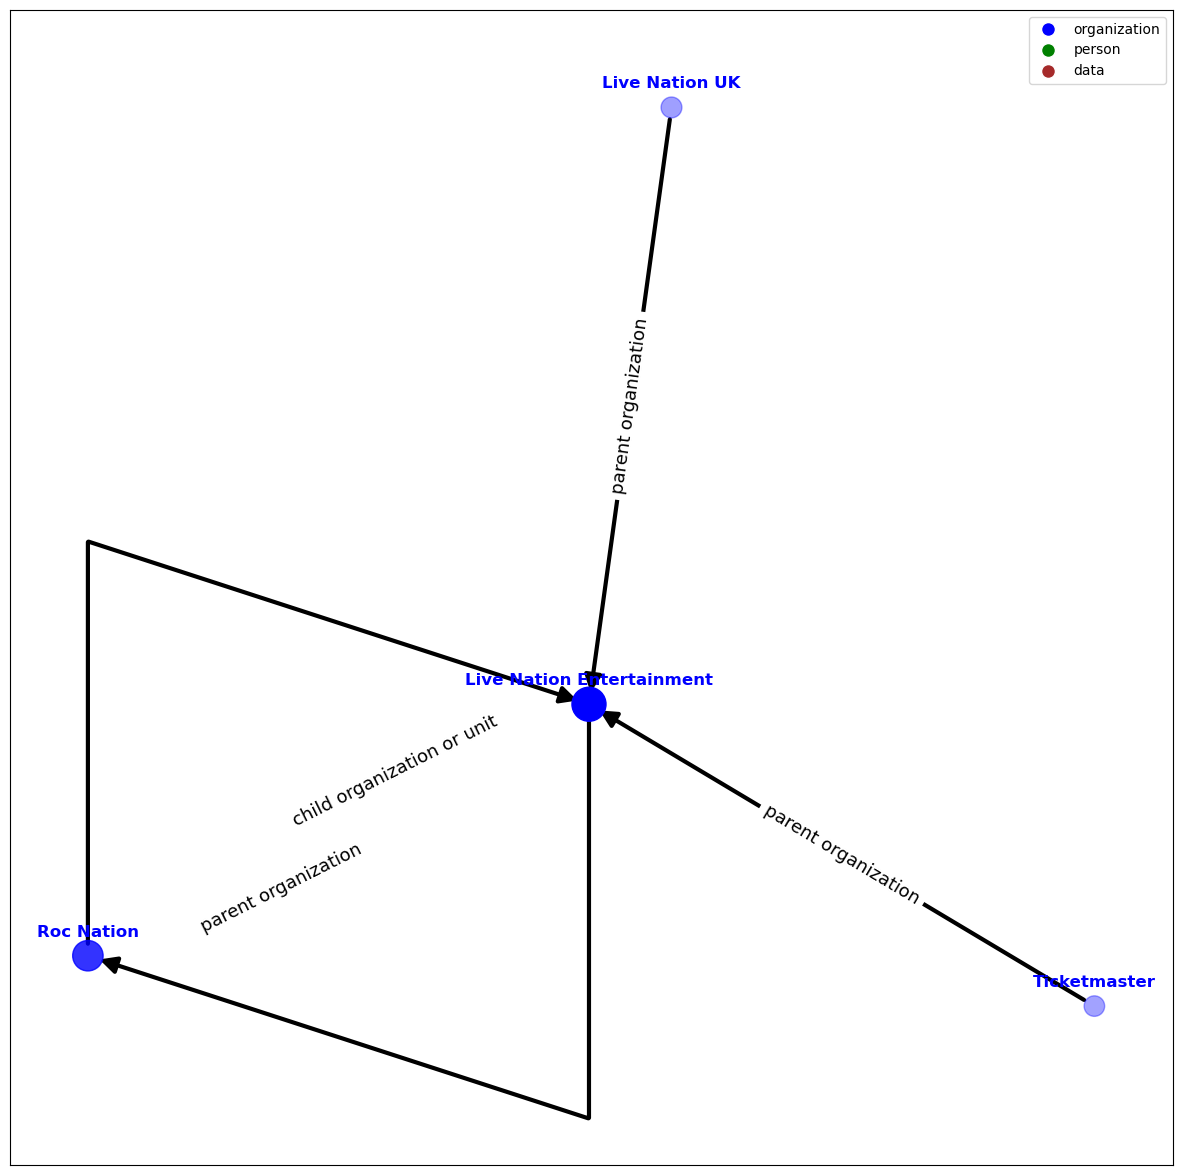

8
[array(['Tohoku University', 'Tohoku Medical Megabank Organization',
       'Tohoku University Repository'], dtype=object), array(['Daisuke Miyata', 'William Tongamp', 'Masaru Kubo', 'Wei Jiao',
       'Junjie Li'], dtype=object)]
['Tohoku University' 'Tohoku Medical Megabank Organization'
 'Tohoku University Repository' 'Daisuke Miyata' 'William Tongamp'
 'Masaru Kubo' 'Wei Jiao' 'Junjie Li']


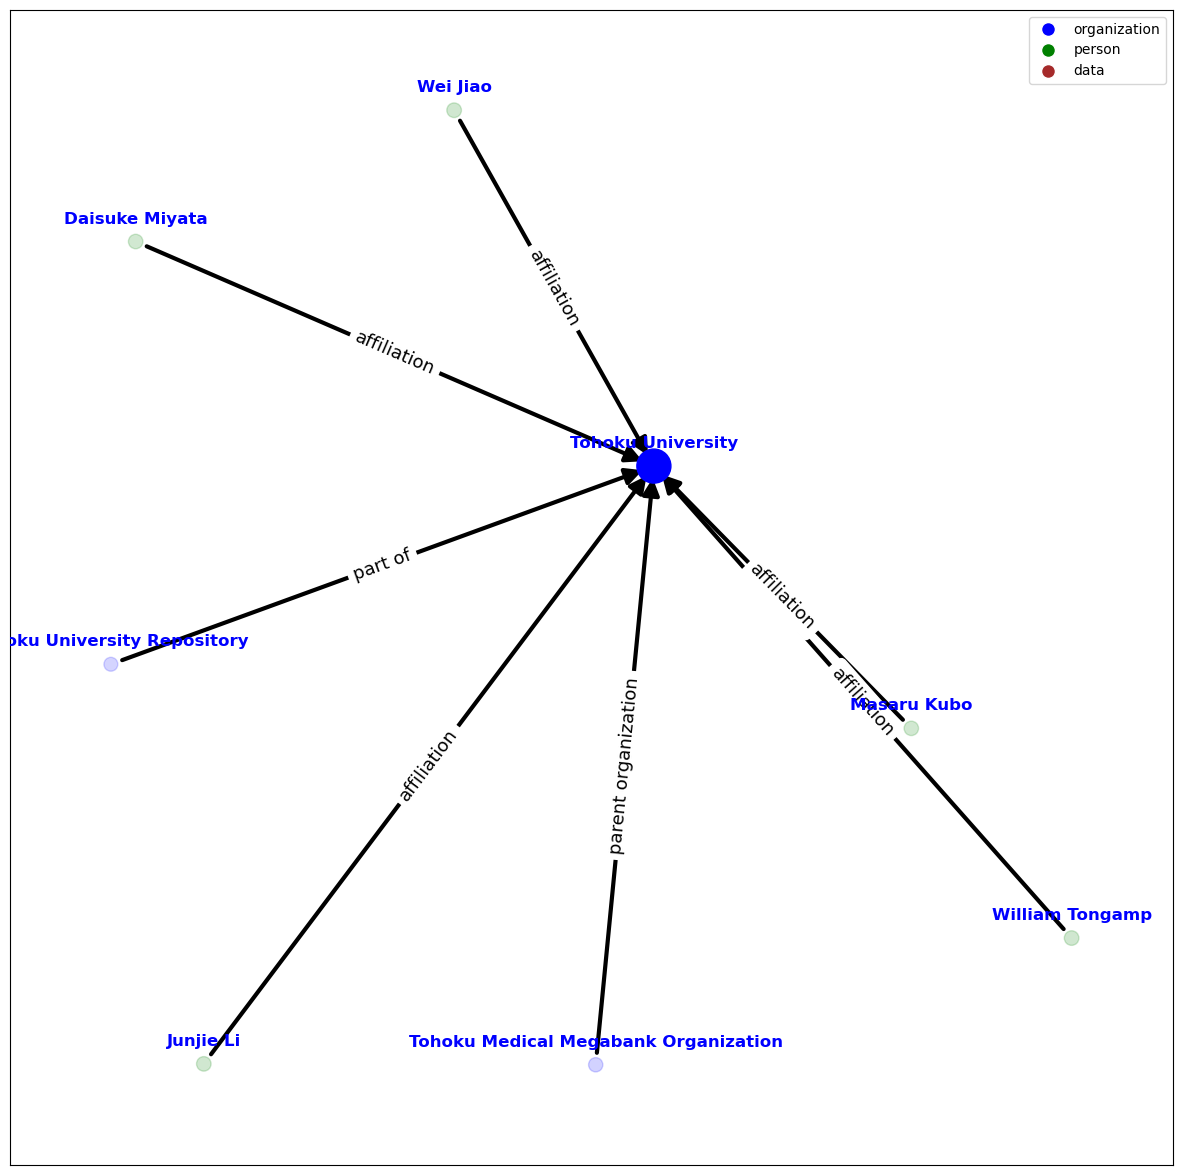

9
[array(['Fox Weather', 'KTTV', 'KCOP-TV'], dtype=object)]
['Fox Weather' 'KTTV' 'KCOP-TV']


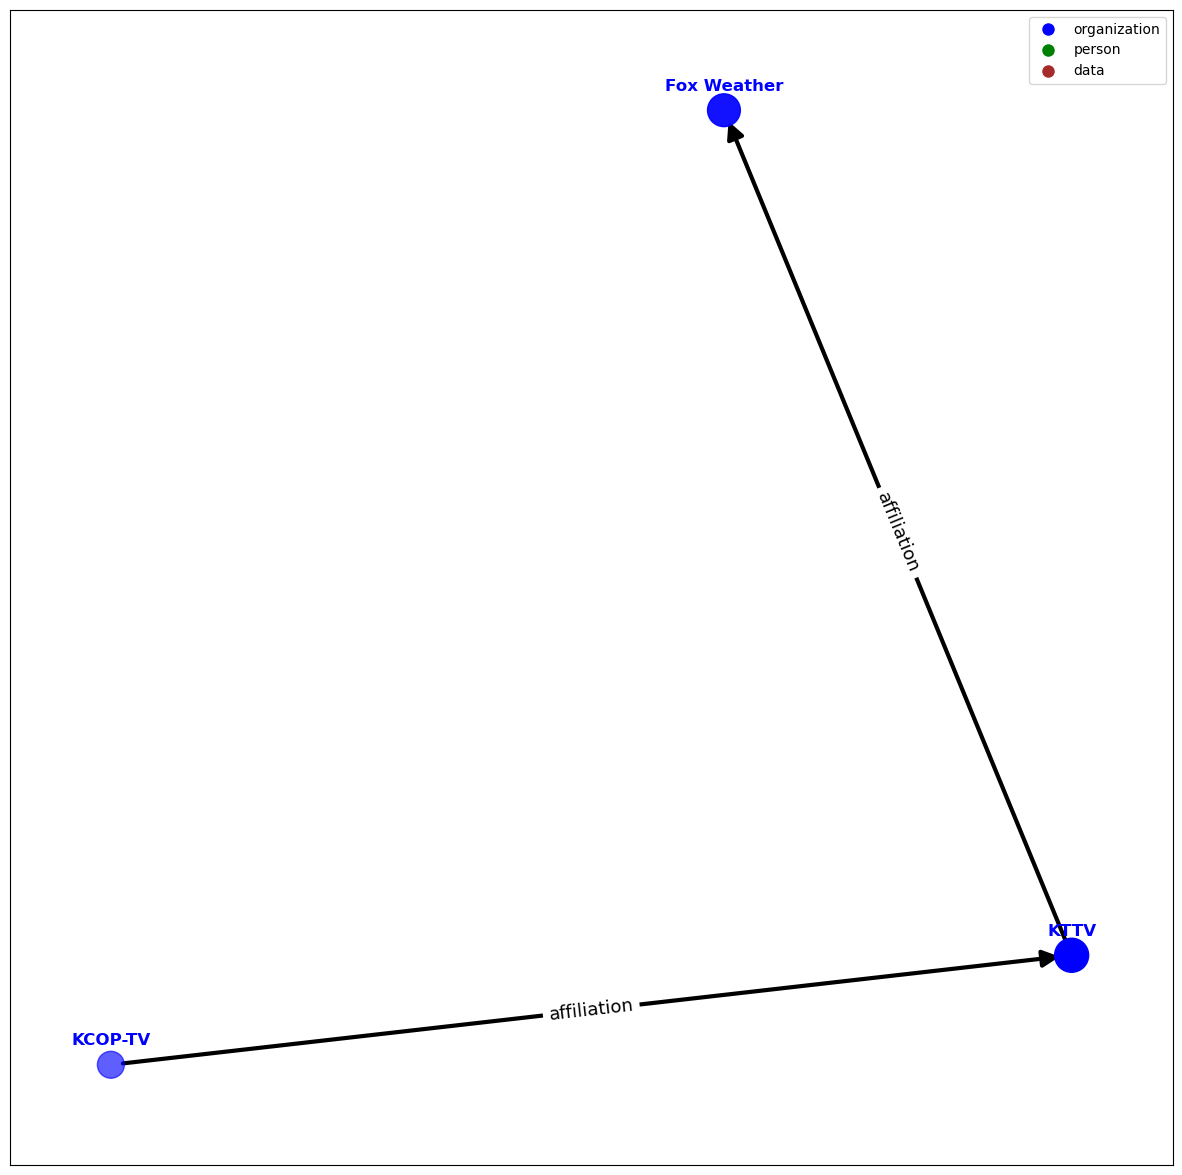

In [79]:
def derive_node_colors_array(node_type_color_map: dict, graph_dict: dict):
    g = graph_dict["g"]
    node_colors = []
    for node_type in g.node_types:
        node_colors += [node_type_color_map[node_type]] * g[node_type].num_nodes
    return node_colors


def derive_asymmetric_and_symmetric_nxs(directed_nx: nx.MultiGraph):
    asymmetric_relations = [
        (edge[0], edge[1])
        for edge in directed_nx.edges
        if (edge[1], edge[0]) not in directed_nx.edges
    ]
    symmetric_nx = deepcopy(directed_nx)
    symmetric_nx.remove_edges_from(asymmetric_relations)
    asymmetric_nx = deepcopy(directed_nx)
    asymmetric_nx.remove_edges_from(symmetric_nx.edges)
    return symmetric_nx, asymmetric_nx


def derive_symmetric_relations_arcs_and_offset_labels(
    graph_dict: dict,
    directed_nx: nx.MultiGraph,
    layout,
    symmetric_nx: nx.MultiGraph,
    asymmetric_nx: nx.MultiGraph,
):
    g = graph_dict["g"]
    pyg_node_offsets = graph_dict["g"].node_offsets
    symmetric_edge_label_dict = {}
    asymmetric_edge_label_dict = {}

    arcs = np.zeros(len(symmetric_nx.edges))
    offsets = np.zeros(len(directed_nx.edges))
    poppable_edge_array = np.array(deepcopy(symmetric_nx.edges))
    if len(poppable_edge_array) > 0:
        while True:
            remaining_edge_idxs = np.argwhere((poppable_edge_array >= 0).all(axis=1))
            if len(remaining_edge_idxs) == 0:
                break
            target_edge = poppable_edge_array[remaining_edge_idxs[0]]
            partner_idxs = [
                i
                for i, edge in enumerate(poppable_edge_array)
                if np.isin(edge.flatten(), target_edge.flatten()).any()
            ]
            arcs[partner_idxs] = np.linspace(
                90.0, 90.0 * len(partner_idxs), len(partner_idxs)
            )
            offsets[partner_idxs] = np.linspace(
                0.05 * len(partner_idxs), -0.05 * len(partner_idxs), len(partner_idxs)
            )
            poppable_edge_array[partner_idxs] = np.array([-1, -2])  # Sentinel
    connection_styles = [f"angle,angleA={ang},angleB={-ang/5},rad=1" for ang in arcs]
    assert len(symmetric_nx.edges) == len(connection_styles), (
        len(symmetric_nx.edges),
        len(connection_styles),
    )

    for source, edge_type, sink in g.edge_types:
        nx_node_coordinate_pairwise_tensor = g[
            source, edge_type, sink
        ].edge_index.T + torch.tensor(
            [pyg_node_offsets[source], pyg_node_offsets[sink]]
        )
        for coo in nx_node_coordinate_pairwise_tensor.tolist():
            coo_tuple = tuple(coo)
            if coo_tuple in symmetric_nx.edges:
                # Recover the nicer looking node labels (PyG requires '
                # ' -> '_')
                symmetric_edge_label_dict[coo_tuple] = edge_type.replace("_", " ")
            elif coo_tuple in asymmetric_nx.edges:
                asymmetric_edge_label_dict[coo_tuple] = edge_type.replace("_", " ")
    return (
        connection_styles,
        offsets,
        asymmetric_edge_label_dict,
        symmetric_edge_label_dict,
    )


def visualize_graph(
    graph_dict: dict,
    path="",
    explanation=None,
    node_importance_mask: Optional[dict] = None,
    edge_importance_mask: Optional[dict] = None,
    num_explanation_nodes=9,
):
    # Inspired by the source code for get_explanation_subgraph()
    if explanation:
        explanation_mask = {
            key: mask.sum(dim=-1) > 0
            for key, mask in explanation.collect("node_mask", True).items()
        }
        g = deepcopy(graph_dict["g"]).subgraph(explanation_mask).to("cpu")
        pruned_graph_dict = associate_pyg_graph_with_homogeneous_undirected_nx_graph(g)
        node_importance_mask = explanation.get_explanation_subgraph().collect(
            "node_mask"
        )
        # g = deepcopy(graph_dict["g"]).to('cpu')
    else:
        g = deepcopy(graph_dict["g"]).to("cpu")

    if node_importance_mask or explanation:
        node_importance_mask = deepcopy(node_importance_mask)
        edge_importance_mask = deepcopy(edge_importance_mask)
        g.generate_ids()  # Adds type-wise indices
        important_nodes_mask = dict.fromkeys(node_importance_mask.keys())
        important_nodes = dict.fromkeys(node_importance_mask.keys())
        # Nodes
        greatest_importance = torch.zeros(1).to(device)
        for node_type in node_importance_mask.keys():
            # Sum node feature importances
            if g[node_type].num_nodes > 0:
                node_importance_mask[node_type] = torch.sum(
                    node_importance_mask[node_type], dim=1
                )
                greatest_importance = max(
                    torch.max(node_importance_mask[node_type]), greatest_importance
                )
        normalized_node_importance_tensors = []
        for i, node_type in enumerate(node_importance_mask.keys()):
            # Normalize node feature importances
            if g[node_type].num_nodes > 0:
                normalized_node_importance_tensors.append(
                    node_importance_mask[node_type] / greatest_importance
                )
            else:
                normalized_node_importance_tensors.append(torch.tensor([]))

        normalized_node_importance_tensor = torch.cat(
            normalized_node_importance_tensors
        )
        num_explanation_nodes = min(num_explanation_nodes, g.num_nodes)
        top_num_explanation_nodes_importances, _ = torch.topk(
            normalized_node_importance_tensor, num_explanation_nodes
        )
        threshold_normalized_importance = top_num_explanation_nodes_importances[-1]
        for i, node_type in enumerate(node_importance_mask.keys()):
            if g[node_type].num_nodes > 0:
                important_nodes_mask[node_type] = (
                    normalized_node_importance_tensors[i]
                    >= threshold_normalized_importance
                )
                important_nodes[node_type] = g[node_type].id[
                    important_nodes_mask[node_type]
                ]

        important_nodes_flat_mask = torch.cat(
            [mask for mask in important_nodes_mask.values() if mask is not None]
        )
        important_nodes_alphas = normalized_node_importance_tensor[
            important_nodes_flat_mask
        ].tolist()
    # if explanation:
    #     for node_type in node_importance_mask.keys():
    #         # Normalize node feature importances
    #         if g[node_type].num_nodes > 0:
    #             normalized_node_importance_tensors.append(
    #                 node_importance_mask[node_type] / greatest_importance
    #             )
    #     normalized_node_importance_tensor = torch.cat(
    #         normalized_node_importance_tensors
    #     )
    # Edges
    if edge_importance_mask:
        important_edges_mask = dict.fromkeys(edge_importance_mask.keys())
        greatest_importance = torch.zeros(1).to(device)
        for source, relation, sink in g.edge_types:  # .keys():
            index = deepcopy(g[source, relation, sink].edge_index)
            index[0] += g.node_offsets[source]
            index[1] += g.node_offsets[sink]
            # important_edges_mask[(source, relation, sink)] = (
            # torch.isin(index.T, top_num_explanation_nodes_indices).any()
            # )
            # Prune the edge mask
            edge_importance_mask[source, relation, sink] = edge_importance_mask[source, relation, sink][important_edges_mask[(source, relation, sink)]]
            if edge_importance_mask[source, relation, sink].shape[0] > 0:
                greatest_importance = max(torch.max(edge_importance_mask[source, relation, sink]), greatest_importance)
        normalized_edge_importance_tensors = []
        for (source, relation, sink) in edge_importance_mask.keys():
            if len(edge_importance_mask[source, relation, sink]):
                normalized_edge_importance_tensors.append(edge_importance_mask[source, relation, sink].squeeze(0) / greatest_importance)
        normalized_edge_importance_tensor = torch.cat(normalized_edge_importance_tensors)
        # g = g.subgraph(important_nodes)
        # pruned_graph_dict = associate_pyg_graph_with_homogeneous_undirected_nx_graph(g)
    else:
        important_nodes_alphas = None
    if not explanation and not node_importance_mask:
        pruned_graph_dict = deepcopy(graph_dict)
    directed_nx = pyg.utils.to_networkx(g)
    plt.figure(figsize=(15, 15))
    plt.xticks([])
    plt.yticks([])
    layout = nx.spring_layout(directed_nx, seed=0)
    # Create a dict of node labels from the original graph that is
    # compatible with nx.draw
    ns = [n for n in directed_nx]
    node_labels = graph_dict_nx_idxs_lookup(pruned_graph_dict, ns, "node_label")

    print(node_labels)

    node_label_dict = {n: node_labels[i] for i, n in enumerate(ns)}
    node_type_color_map = {
        "organization": "blue",
        "person": "green",
        "data": "brown",
    }
    node_colors = derive_node_colors_array(node_type_color_map, pruned_graph_dict)
    # We have to spend some extra time making heterogeneous i.e.
    # overlapping edges look nice

    # Create a mapping from directed nx edges to a linear mapping for use in
    # deriving edge alphas
    if node_importance_mask:
        nx_edge_to_serial_idx_map = dict(zip(directed_nx.edges, range(len(directed_nx.edges))))
    symmetric_nx, asymmetric_nx = derive_asymmetric_and_symmetric_nxs(directed_nx)
    (
        connection_styles,
        offsets,
        asymmetric_edge_label_dict,
        symmetric_edge_label_dict,
    ) = derive_symmetric_relations_arcs_and_offset_labels(
        pruned_graph_dict, directed_nx, layout, symmetric_nx, asymmetric_nx
    )
    nx.draw_networkx_nodes(
        directed_nx,
        pos=layout,
        node_color=node_colors,
        alpha=normalized_node_importance_tensor,
        # Default node size is 300. Let the highest-influencing node be
        # twice that and the rest follow.
        node_size=(
            [alpha * 600 for alpha in normalized_node_importance_tensor]
        ),
    )
    # Draw the asymmetric relations
    if edge_importance_mask:
        asymmetric_alphas = normalized_edge_importance_tensor[torch.tensor([
            nx_edge_to_serial_idx_map[edge]
            for edge in asymmetric_nx.edges
        ])]
    else:
        asymmetric_alphas = None
    nx.draw_networkx_edges(
        asymmetric_nx,
        pos=layout,
        width=3,
        arrowsize=25,
        alpha=asymmetric_alphas,
    )
    # Draw the symmetric relations
    if edge_importance_mask:
        symmetric_alphas = normalized_edge_importance_tensor[torch.tensor([
        nx_edge_to_serial_idx_map[edge]
        for edge in symmetric_nx.edges
        ])]
    else:
        symmetric_alphas = None
    nx.draw_networkx_edges(
        symmetric_nx,
        pos=layout,
        width=3,
        arrowsize=25,
        connectionstyle=connection_styles,
        alpha=symmetric_alphas,
    )
    # We draw labels seperately for better control on their positioning.
    idx_label_coord_pair_dict = {
        idx: arr + np.array([0.0, 0.04])
        for idx, arr in nx.spring_layout(directed_nx, seed=0).items()
    }
    nx.draw_networkx_labels(
        directed_nx,
        pos=idx_label_coord_pair_dict,
        labels=node_label_dict,
        font_color="blue",
        font_weight=600,
    )
    # Draw the asymmetric labels
    nx.draw_networkx_edge_labels(
        asymmetric_nx,
        pos=layout,
        edge_labels=asymmetric_edge_label_dict,
        font_size=13,
    )
    # Draw the symmetric labels
    draw_networkx_edge_labels_with_offsets(
        symmetric_nx,
        pos=layout,  # _with_symmetric_relation_offsets,
        edge_labels=symmetric_edge_label_dict,
        font_size=13,
        offsets=offsets,
    )
    plt.legend(
        handles=[
            plt.Line2D(
                [0],
                [0],
                marker="o",
                color="w",
                label=label,
                markerfacecolor=color,
                markersize=10,
            )
            for label, color in node_type_color_map.items()
        ]
    )
    if path:
        plt.savefig(path)
    plt.show()


g_nuni_two_hop_dict_full_debug["g"] = g_nuni_two_hop_dict_full_debug["g"].to("cpu")
g_nuni_two_hop_dict["g"] = g_nuni_two_hop_dict["g"].to("cpu")


visualize_graph(g_nuni_two_hop_dict, explanation=explanations[8].to("cpu"))

for i, explanation in enumerate(explanations):
    # explanation_subgraph = explanation.get_explanation_subgraph()
    print(i)
    # try:
    visualize_graph(g_nuni_two_hop_dict, explanation=explanation.to('cpu'), path=f"explanation_{i}")
    # except:
        # continue

In [64]:
explanations

[HeteroExplanation(
   prediction=[18048],
   target=[18048],
   index=[1],
   organization={
     node_mask=[11146, 260],
     x=[11146, 260],
   },
   data={
     node_mask=[4200, 260],
     x=[4200, 260],
   },
   person={
     node_mask=[2702, 260],
     x=[2702, 260],
   },
   (organization, affiliation, organization)={ edge_index=[2, 1463] },
   (organization, approved_by, organization)={ edge_index=[2, 3] },
   (organization, donated_by, organization)={ edge_index=[2, 1] },
   (organization, has_parts, organization)={ edge_index=[2, 566] },
   (organization, child_organization_or_unit, organization)={ edge_index=[2, 643] },
   (organization, parent_organization, organization)={ edge_index=[2, 1231] },
   (organization, part_of, organization)={ edge_index=[2, 1248] },
   (organization, partnership_with, organization)={ edge_index=[2, 250] },
   (organization, sponsor, organization)={ edge_index=[2, 225] },
   (organization, maintained_by, organization)={ edge_index=[2, 13] },
   

In [ ]:
print(explanations)

[HeteroExplanation(
  prediction=[18048],
  target=[18048],
  index=[1],
  organization={
    node_mask=[11146, 260],
    x=[11146, 260],
  },
  data={
    node_mask=[4200, 260],
    x=[4200, 260],
  },
  person={
    node_mask=[2702, 260],
    x=[2702, 260],
  },
  (organization, affiliation, organization)={ edge_index=[2, 1463] },
  (organization, approved_by, organization)={ edge_index=[2, 3] },
  (organization, donated_by, organization)={ edge_index=[2, 1] },
  (organization, has_parts, organization)={ edge_index=[2, 566] },
  (organization, child_organization_or_unit, organization)={ edge_index=[2, 643] },
  (organization, parent_organization, organization)={ edge_index=[2, 1231] },
  (organization, part_of, organization)={ edge_index=[2, 1248] },
  (organization, partnership_with, organization)={ edge_index=[2, 250] },
  (organization, sponsor, organization)={ edge_index=[2, 225] },
  (organization, maintained_by, organization)={ edge_index=[2, 13] },
  (organization, member_of, 

 Cross-validation

In [ ]:
test_scores = []
for i in range(10):
    g_uni_dict, g_uni_feature_map = dataset_to_graph_dict(g_uni_df_debug, wikifake_uni_df_debug, keep_isolated_nodes=False, impute_missing_scores_with="mean", mode="compact", fold=i)


    data_train_loader = pyg.loader.NeighborLoader(
        data=g,
        input_nodes=("data", g["data"].train_mask),
        num_neighbors=num_neighbors,
        batch_size=batch_size,
    )
    organization_train_loader = pyg.loader.NeighborLoader(
        data=g,
        input_nodes=("organization", g["organization"].train_mask),
        num_neighbors=num_neighbors,
        batch_size=batch_size,
    )
    person_train_loader = pyg.loader.NeighborLoader(
        data=g,
        input_nodes=("person", g["person"].train_mask),
        num_neighbors=num_neighbors,
        batch_size=batch_size,
    )

    data_validation_loader = pyg.loader.NeighborLoader(
        data=g,
        input_nodes=("data", g["data"].validation_mask),
        num_neighbors=num_neighbors,
        batch_size=batch_size,
    )
    organization_validation_loader = pyg.loader.NeighborLoader(
        data=g,
        input_nodes=("organization", g["organization"].validation_mask),
        num_neighbors=num_neighbors,
        batch_size=batch_size,
    )
    person_validation_loader = pyg.loader.NeighborLoader(
        data=g,
        input_nodes=("person", g["person"].validation_mask),
        num_neighbors=num_neighbors,
        batch_size=batch_size,
    )

    train_loaders = [
        data_train_loader,
        organization_train_loader,
        person_train_loader,
    ]
    validation_loaders = [
        data_validation_loader,
        organization_validation_loader,
        person_validation_loader,
    ]
    # with open("model", "rb") as f:
    #     model = pickle.load(f)
    model = pyg.nn.to_hetero(
        WikifakeCGNN(
            g,
            size_factor_series = bottleneck,  # [4, 4, 0.25, 0.25]
            skip = False,
            skip_linear= skip_linear,
            directed_msg = directed_msg,
            batch_norm = batch_norm, #batch_norm,
        ),
        g.metadata(),
        aggr=aggr,
    ).to(device)

    optimizer = torch.optim.AdamW(model.parameters(), lr=lr)
    _, validation_losses, epoch = train_validate_run(
        model,
        train_loaders,
        validation_loaders,
        optimizer,
        scaler,
        "Wikifake-GCNN",
        loss_weighing=None,
        early_stopping=False,
        g_dict=g_uni_dict_debug,
        epochs=epochs,
        verbose=True,
    )
    test_scores.append(validation_losses[-1])

For ('data', 'affiliation', 'data'), used edge index
tensor([[1659, 1718, 1719, 5258, 5528, 1049,  824,  644],
        [1108, 1719, 1718, 2095, 4293, 4795, 1120,  623]]) with sink score tensor
tensor([1.0000, 1.0000, 1.0000,  ..., 0.6149, 0.6149, 0.6149])
to generated score scatter
tensor([0., 0., 0.,  ..., 0., 0., 0.])
with counts
tensor([0., 0., 0.,  ..., 0., 0., 0.])


Before update:
Count:
tensor([[0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        ...,
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.]])

Mean:
tensor([[0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        ...,
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.]])



After update:
tensor([0., 0., 0.,  ..., 0., 0., 0.])

Count:
tensor([[0., 0., 0.,  ..

TypeError: can't convert np.ndarray of type numpy.object_. The only supported types are: float64, float32, float16, complex64, complex128, int64, int32, int16, int8, uint64, uint32, uint16, uint8, and bool.